<div style="border:solid Chocolate 2px; padding: 40px">

<b>Привет!</b>

Меня зовут Евгений Головин, я буду ревьюером твоего проекта. Если ты не против, то предлагаю построить наше общение на "ты" ;) Если удобнее на "вы", то нет проблем, только скажи об этом. 

В ходе работы я оставил тебе комментарии <font color='green'>зеленого</font>, <font color='gold'>желтого</font> и <font color='red'>красного</font> цветов. Сейчас объясню, что они значат:

<br/>

<div class="alert alert-success">
<h2> Комментарий ревьюера <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Решение на этом шаге является полностью правильным.
</div>

<br/>

<div class="alert alert-warning">
    <h2> Комментарий ревьюера <a class="tocSkip"> </h2>
    
<b>Небольшие замечания и рекомендации💡:</b> Решение на этом шаге станет еще лучше, если внести небольшие коррективы.
</div>


<br/>
<div class="alert alert-block alert-danger">
<h2> Комментарий ревьюера <a class="tocSkip"></h2>

    
<b>На доработку🤔:</b>
 Решение на этом шаге требует существенной переработки и внесения правок. Напоминаю, что проект не может быть принят с первого раза, если ревью содержит комментарии, рекомендующие доработать шаги.
</div>
    
Увидев мой комментарий, не удаляй его, он будет очень полезен в случае повторной проверки работы :)
    
<div class="alert alert-info">
<b>А свой помечай вот так, чтобы я его не потерял ;)</b> 
</div>
    
На мои комменатрии можно и нужно реагировать, только делать это стоит так, чтобы твои и мои комменты не смешались: выделяй свои цветами, сильно отличающимися от моих.
    
Увидев у тебя неточность, в первый раз я лишь укажу на ее наличие и дам тебе возможность самому найти и исправить ее. На реальной работе твой руководитель будет поступать также, и я пытаюсь подготовить тебя именно к работе аналитиком. Но если ты пока не справишься с такой задачей - при следующей проверке я дам более точную подсказку!
</div>

# Проект: семантический поиск товаров по текстовому запросу

**Ваша роль.** Вы специалист по Data Science. Компания развивает онлайн-каталог товаров, и сейчас руководству кажется, что классический поиск по ключевым словам плохо справляется с реальными запросами. Пользователи пишут названия с ошибками, кириллицей, используют просторечные слова, ищут товары по назначению, а не по функциональности («удобные кроссовки для бега» вместо «мужские спортивные кроссовки с амортизацией»). Команда хочет проверить, поможет ли векторный поиск улучшить качество поисковой системы.

**Задача.** Вам нужно построить MVP системы семантического поиска, сравнить его с лексической baseline-моделью на подготовленной разметке и дать бизнесу обоснованную рекомендацию о том, где новое решение помогает, где ошибается и стоит ли его вообще внедрять.

## Данные

| Файл | Что это | Когда нужен |
|---|---|---|
| wb_products_raw_sample.parquet | Исходный каталог, ~200 тысяч строк, все категории. <br> Вам нужно самостоятельно отобрать рабочее подмножество этих данных | Недели 1–2 |
| wb_products_dedup.parquet | Пул асессоров: множество товаров, по которому делалась разметка | Неделя 2, раздел 4 |
| queries_synthetic_train.parquet | Разметка релевантности, train | Недели 2–3 |
| queries_synthetic_test.parquet | Разметка релевантности, test | **один прогон** в конце недели 3 |

Файлы с разметкой содержат четыре столбца: `query_id`, `query_text`, `item_id`, `relevance`. Шкала в `relevance` от `0` до `3`, где `0` — товар нерелевантен, а `3` — максимально релевантен. Связь с каталогом: `item_id` ↔ `imt_id`.

In [1]:
import sys
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import boto3
from dotenv import load_dotenv

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

In [2]:
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)


RAW_PRODUCTS_PATH = DATA_DIR / "wb_products_raw_sample.parquet"
ASSESSED_POOL_PATH = DATA_DIR / "wb_products_dedup.parquet"
TRAIN_QUERIES_PATH = DATA_DIR / "queries_synthetic_train.parquet"
TEST_QUERIES_PATH = DATA_DIR / "queries_synthetic_test.parquet"

---

## Неделя 1 — знакомство с данными и EDA

**Цель** — понять, с какими данными работаете, чтобы принять обоснованные решения:

- выбрать категории, с которыми будете работать;
- определить, как будете очищать описания от всего лишнего;
- решить, из каких полей собирать текст товара.

**Главный критерий успеха:** любое ваше решение по данным вы можете подкрепить ссылкой на конкретные результаты анализа.

### 1. Загрузка данных

Загрузите каталог и обе разметки. Изучите их структуру: проанализируйте колонки и типы данных в них, определите, что описывает одна строка.

**Подсказка.** `imt_id` — карточка товара, `nm_id` — конкретный артикул этого товара, то есть его разновидность, отличающаяся цветом, размером или чем-то ещё. Определите, что из этого должен возвращать поиск, — от этого зависит, на каком уровне вы будете строить индекс.

In [3]:
import os

# Читаем параметры доступа
load_dotenv(override=True)

access_key = os.getenv("AWS_ACCESS_KEY_ID")
secret_key = os.getenv("AWS_SECRET_ACCESS_KEY")
endpoint = os.getenv("S3_ENDPOINT_URL")
source_bucket = os.getenv("S3_SOURCE_BUCKET")

if not all([access_key, secret_key, endpoint, source_bucket]):
    raise ValueError("В файле .env заполнены не все параметры доступа к S3.")

# Подключаемся к S3
s3 = boto3.client(
    "s3",
    endpoint_url=endpoint,
    aws_access_key_id=access_key,
    aws_secret_access_key=secret_key,
    region_name="ru-central1",
)

# Скачиваем только отсутствующие файлы
for path in [RAW_PRODUCTS_PATH, TRAIN_QUERIES_PATH, TEST_QUERIES_PATH]:
    if not path.exists():
        s3.download_file(source_bucket, path.name, str(path))

In [4]:
df_raw = pd.read_parquet(RAW_PRODUCTS_PATH)
queries_train = pd.read_parquet(TRAIN_QUERIES_PATH)
queries_test = pd.read_parquet(TEST_QUERIES_PATH)

# Ваш код: размеры, колонки, типы, первые строки
# Размеры загруженных таблиц
print("Каталог:", df_raw.shape)
print("Тренировочная разметка:", queries_train.shape)
print("Тестовая разметка:", queries_test.shape)

# Столбцы, типы данных и количество непустых значений
df_raw.info()

# Первые пять строк каталога
display(df_raw.head())

Каталог: (200000, 9)
Тренировочная разметка: (11453, 4)
Тестовая разметка: (4866, 4)
<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column           Non-Null Count   Dtype
---  ------           --------------   -----
 0   imt_id           200000 non-null  int64
 1   nm_id            200000 non-null  int64
 2   imt_name         200000 non-null  str  
 3   subj_name        200000 non-null  str  
 4   subj_root_name   200000 non-null  str  
 5   nm_colors_names  200000 non-null  str  
 6   vendor_code      200000 non-null  str  
 7   description      200000 non-null  str  
 8   brand_name       200000 non-null  str  
dtypes: int64(2), str(7)
memory usage: 169.5 MB


,imt_id,nm_id,imt_name,subj_name,subj_root_name,nm_colors_names,vendor_code,description,brand_name
0,100000,118982,Сумка,Сумки,Аксессуары,бежевый,82992/beige,,Pola
1,1000000,1206857,Шапка,Шапки,Головные уборы,белый,Лаки/белый,,Ваша Шляпка
2,1000000,1206860,Шапка,Шапки,Головные уборы,черный,Лаки/черный,,Ваша Шляпка
3,10000000,13349975,Очки TRUESPIN Fold,Солнцезащитные очки,Аксессуары,черный,20S.Y.T.35.00.564/Black/Black,,True Spin
4,10000001,13349981,Очки TRUESPIN Candor,Солнцезащитные очки,Аксессуары,черный,20S.Y.T.35.00.567/Black,,True Spin


In [5]:
queries_train.info()

# Первые пять пар «запрос — товар»
display(queries_train.head())

# Количество уникальных запросов и товаров
print("Уникальных запросов:", queries_train["query_id"].nunique())
print("Уникальных товаров:", queries_train["item_id"].nunique())

<class 'pandas.DataFrame'>
RangeIndex: 11453 entries, 0 to 11452
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   query_id    11453 non-null  str  
 1   query_text  11453 non-null  str  
 2   item_id     11453 non-null  int64
 3   relevance   11453 non-null  int64
dtypes: int64(2), str(2)
memory usage: 854.8 KB


,query_id,query_text,item_id,relevance
0,SYN_000001,жилеты на пуговицах,100211,3
1,SYN_000001,жилеты на пуговицах,100433,1
2,SYN_000001,жилеты на пуговицах,1000988,1
3,SYN_000001,жилеты на пуговицах,1016032,1
4,SYN_000001,жилеты на пуговицах,10001023,1


Уникальных запросов: 700
Уникальных товаров: 2285


**Проверьте связность данных:** все ли `item_id` из разметки есть в каталоге, нет ли пересечения `query_id` между `train` и `test`.

In [6]:
# Ваш код
# Товары из разметки, которых нет в исходном каталоге
catalog_ids = set(df_raw["imt_id"])

missing_train = set(queries_train["item_id"]) - catalog_ids
missing_test = set(queries_test["item_id"]) - catalog_ids

print("Товаров train вне каталога:", len(missing_train))
print("Товаров test вне каталога:", len(missing_test))

# Пересечение идентификаторов запросов
common_query_ids = (
    set(queries_train["query_id"]) & set(queries_test["query_id"])
)
print("Общих query_id между train и test:", len(common_query_ids))

# Пересечение текстов запросов: без учёта регистра и лишних пробелов
train_texts = (
    queries_train["query_text"]
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)
test_texts = (
    queries_test["query_text"]
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

common_query_texts = set(train_texts) & set(test_texts)
print("Общих текстов запросов между train и test:", len(common_query_texts))

Товаров train вне каталога: 0
Товаров test вне каталога: 0
Общих query_id между train и test: 0
Общих текстов запросов между train и test: 0


<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Хорошее начало. Ключи доступа читаются из <code>.env</code>, а не лежат в ноутбуке, есть проверка, что все параметры заполнены, и файлы скачиваются только если их ещё нет на диске. Сид зафиксирован в первой же ячейке.

Отдельно отмечу проверку связности: ты сравнил train и test не только по <code>query_id</code>, но и по нормализованному тексту запроса. Одинаковый запрос вполне мог получить разные идентификаторы, и проверка только по id такую утечку не поймала бы. До этого додумываются немногие.

Пара мелочей на будущее:
<ul>
<li>импорты разбросаны по ноутбуку (<code>os</code>, <code>re</code>, <code>html</code>, <code>sklearn</code>, <code>sentence_transformers</code>, <code>mlflow</code> появляются по ходу дела), а <code>sys</code> и <code>seaborn</code> нигде не используются. Удобнее собрать всё в первой ячейке: сразу видно, что нужно установить для запуска;</li>
<li>тестовую разметку ты загрузил, но не посмотрел даже на её структуру. Заглянуть в <code>info()</code> и число уникальных запросов можно без риска: это не подбор параметров.</li>
</ul>
</div>

### 2. EDA

In [7]:
# Ваш код
# Объём каталога и уникальные идентификаторы
print("Всего строк:", len(df_raw))
print("Уникальных карточек imt_id:", df_raw["imt_id"].nunique())
print("Уникальных артикулов nm_id:", df_raw["nm_id"].nunique())

# Полные дубликаты: совпадение всех столбцов
print("Полных дубликатов:", df_raw.duplicated().sum())

# Повторные строки по идентификаторам, кроме первого вхождения
print("Повторов imt_id:", df_raw.duplicated(subset=["imt_id"]).sum())
print("Повторов nm_id:", df_raw.duplicated(subset=["nm_id"]).sum())

# Количество разных артикулов у каждой карточки
variants_per_card = df_raw.groupby("imt_id")["nm_id"].nunique()

print("Карточек с несколькими артикулами:", (variants_per_card > 1).sum())
print("Максимум артикулов у одной карточки:", variants_per_card.max())

Всего строк: 200000
Уникальных карточек imt_id: 174427
Уникальных артикулов nm_id: 199957
Полных дубликатов: 0
Повторов imt_id: 25573
Повторов nm_id: 43
Карточек с несколькими артикулами: 10632
Максимум артикулов у одной карточки: 30


In [8]:
# Все строки с повторяющимися nm_id, включая первое вхождение
duplicate_articles = df_raw[
    df_raw.duplicated(subset=["nm_id"], keep=False)
].sort_values(["nm_id", "imt_id"])

print("Артикулов с повторами:", duplicate_articles["nm_id"].nunique())
print("Строк для этих артикулов:", len(duplicate_articles))

# Поля, значения которых отличаются внутри одного nm_id
differences = (
    duplicate_articles.groupby("nm_id")
    .nunique(dropna=False)
)

print("Количество артикулов с различиями по каждому полю:")
display((differences > 1).sum())

# Все строки для первых трёх повторяющихся артикулов
example_ids = duplicate_articles["nm_id"].unique()[:3]
display(
    duplicate_articles[
        duplicate_articles["nm_id"].isin(example_ids)
    ]
)

Артикулов с повторами: 43
Строк для этих артикулов: 86
Количество артикулов с различиями по каждому полю:


imt_id              0
imt_name           13
subj_name           5
subj_root_name      0
nm_colors_names    19
vendor_code         0
description        19
brand_name          0
dtype: int64

,imt_id,nm_id,imt_name,subj_name,subj_root_name,nm_colors_names,vendor_code,description,brand_name
92826,10084538,11549279,"Гречка в варочных пакетах, 500г",Гречка,Продукты,,A37,Крупа гречневая ядрица. Первая в России гречне...,АРИВЕРА
92827,10084538,11549279,"Органическая гречка в варочных пакетах, 500 г",Гречка,Продукты,,A37,Гречка пропаренная АРИВЕРА БИО - это первая в ...,АРИВЕРА
133185,101226440,12009721,Серьги с бирюзой натуральной,Ювелирные серьги,Ювелирные украшения,"бирюзовый, золотистый, голубой",221684б0,"Комплектное кольцо арт. 12009720, комплектная ...",Елана
133186,101226440,12009721,Серьги с бирюзой натуральной,Ювелирные серьги,Ювелирные украшения,"золотистый, голубой, бирюзовый",221684б0,"Комплектное кольцо арт. 12009720, комплектная ...",Елана
11709,100108876,12465248,"Шпатель кондитерский ""Волны"", 13.5х10см",Шпатели кондитерские,Посуда и инвентарь,белый,1426890,Шпатель кондитерский Волны - Кулинарные принад...,Mellingward
11710,100108876,12465248,"Шпатель кондитерский ""Волны"", 13.5х10см",Шпатели кондитерские,Посуда и инвентарь,белый,1426890,Шпатель кондитерский Волны - Кулинарные принад...,Mellingward


In [9]:
# Проверяем полноту текстовых полей
text_columns = [
    "imt_name",
    "subj_name",
    "subj_root_name",
    "nm_colors_names",
    "vendor_code",
    "description",
    "brand_name",
]

missing_summary = []

for column in text_columns:
    values = df_raw[column]

    null_count = values.isna().sum()
    empty_count = values.fillna("").str.strip().eq("").sum() - null_count
    total_missing = null_count + empty_count

    missing_summary.append({
        "Поле": column,
        "NaN": null_count,
        "Пустые строки и пробелы": empty_count,
        "Всего пропусков": total_missing,
        "Доля пропусков, %": round(total_missing / len(df_raw) * 100, 2),
    })

missing_summary = pd.DataFrame(missing_summary)
display(missing_summary)

,Поле,NaN,Пустые строки и пробелы,Всего пропусков,"Доля пропусков, %"
0,imt_name,0,708,708,0.35
1,subj_name,0,8,8,0.00
2,subj_root_name,0,8,8,0.00
3,nm_colors_names,0,34226,34226,17.11
4,vendor_code,0,6646,6646,3.32
5,description,0,57509,57509,28.75
6,brand_name,0,201,201,0.10


In [10]:
# Проверяем отсутствие названия и описания
missing_name = df_raw["imt_name"].fillna("").str.strip().eq("")
missing_description = df_raw["description"].fillna("").str.strip().eq("")

# Признак для последующего анализа качества поиска
df_raw["has_description"] = ~missing_description

# Строки без названия и описания одновременно
missing_both = missing_name & missing_description

print("Строк без названия и описания:", missing_both.sum())
print(
    "Уникальных imt_id в этих строках:",
    df_raw.loc[missing_both, "imt_id"].nunique(),
)

display(
    df_raw.loc[
        missing_both,
        ["imt_id", "nm_id", "imt_name", "description", "subj_name"],
    ].head(10)
)

Строк без названия и описания: 163
Уникальных imt_id в этих строках: 160


,imt_id,nm_id,imt_name,description,subj_name
2390,10002112,13352568,,,Циркули
2947,10002583,13353346,,,Шорты
2948,10002584,13353347,,,Шорты
19428,10017414,13374175,,,Брюки
20237,10018304,13375293,,,Брюки
20627,10018642,13375790,,,Джинсы
23207,10020857,13378929,,,Рубашки
25255,10022720,13381544,,,Искусственные растения
25256,10022721,13381538,,,Искусственные растения
29773,10026811,13387582,,,Бриджи


In [11]:
# Есть ли хотя бы в одной строке карточки название или описание
card_has_text = (
    df_raw.assign(has_text=~missing_both)
    .groupby("imt_id")["has_text"]
    .any()
)

# Карточки, у которых все строки без названия и описания
empty_card_ids = card_has_text.index[~card_has_text]

print("Полностью пустых карточек:", len(empty_card_ids))
print(
    "Карточек с пустыми строками, но с текстом в других строках:",
    df_raw.loc[missing_both, "imt_id"].nunique() - len(empty_card_ids),
)

# Есть ли полностью пустые карточки в тренировочной разметке
print(
    "Полностью пустых карточек в train:",
    queries_train.loc[
        queries_train["item_id"].isin(empty_card_ids), "item_id"
    ].nunique(),
)

Полностью пустых карточек: 157
Карточек с пустыми строками, но с текстом в других строках: 3
Полностью пустых карточек в train: 0


<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Очень аккуратный разбор дубликатов и пропусков:
<ul>
<li>ты не остановился на «повторов <code>nm_id</code> — 43», а посмотрел, чем именно различаются такие строки. Видно, что <code>imt_id</code>, бренд и артикул продавца совпадают, а меняются название, цвет и описание, то есть это разные версии одной карточки;</li>
<li>пропуски посчитаны и как <code>NaN</code>, и как пустые строки. В этом каталоге <code>isna()</code> показал бы ноль по всем полям, хотя без описания почти 29% строк. На этом месте ошибаются часто;</li>
<li>проверка «пустая карточка целиком или только одна из её строк» и сверка пустых карточек с разметкой заранее отвечают на вопрос, не потеряем ли мы размеченные товары при отсеве.</li>
</ul>
Единственное, чего здесь не хватает, это пары строк текстом после таблицы с дубликатами <code>nm_id</code>: что ты из неё понял и как это повлияет на дедупликацию. Сейчас вывод приходится додумывать читателю.
</div>

In [12]:
# Распределение по корневым категориям
root_categories = (
    df_raw.groupby("subj_root_name")
    .agg(
        rows=("imt_id", "size"),
        cards=("imt_id", "nunique"),
    )
    .sort_values("cards", ascending=False)
)

# Распределение по предметным категориям внутри каждого корня
subject_categories = (
    df_raw.groupby(["subj_root_name", "subj_name"])
    .agg(
        rows=("imt_id", "size"),
        cards=("imt_id", "nunique"),
    )
    .sort_values("cards", ascending=False)
)

print("Корневых категорий с заполненным названием:",
      df_raw.loc[
          df_raw["subj_root_name"].str.strip().ne(""),
          "subj_root_name"
      ].nunique())

print("Топ-20 корневых категорий:")
display(root_categories.head(20))

print("Топ-20 предметных категорий:")
display(subject_categories.head(20))

Корневых категорий с заполненным названием: 64
Топ-20 корневых категорий:


,rows,cards
subj_root_name,,
Одежда,43316,36965
Дом,15024,13482
Аксессуары,16446,13230
Обувь,13187,11524
Красота,9895,9152
Посуда и инвентарь,7799,7246
Смартфоны и аксессуары,6997,5558
Игрушки,5411,4944
Белье,6066,4795


Топ-20 предметных категорий:


rows  cards
subj_root_name            subj_name                               
Одежда                    Платья                       6998   6113
                          Футболки                     5465   4524
Аксессуары                Сумки                        5215   4051
Одежда                    Брюки                        3427   2858
Дом                       Постельное белье             2457   2342
Смартфоны и аксессуары    Чехлы для телефонов          3169   2189
Автомобильные товары      Автомобильные ароматизаторы  2165   2157
Одежда                    Блузки                       2342   2076
                          Костюмы                      2317   2025
Обувь                     Туфли                        2159   2013
Ювелирные украшения       Ювелирные серьги             1799   1664
Одежда                    Джинсы                       1746   1661
Книжная продукция и диски Книги                        1693   1647
Ювелирные украшения       Ювелирные кольца             1717   1592
Дом                       Светильники                  1526   1494
Аксессуары                Рюкзаки                      1688   1489
Обувь                     Кроссовки                    1835   1476
Одежда                    Юбки                         1647   1471
                          Рубашки                      1689   1444
Обувь                     Ботинки                      1502   1349

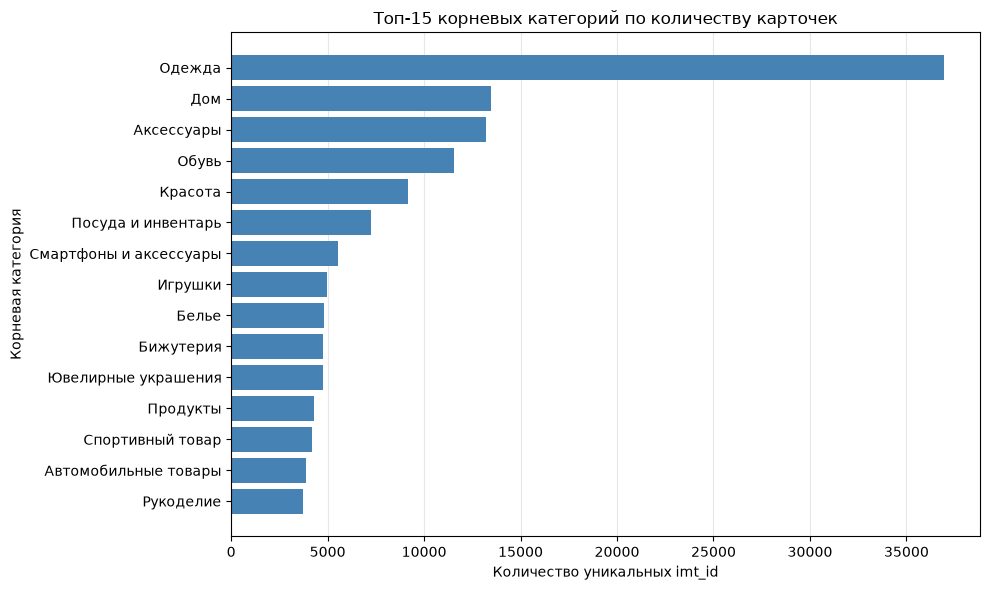

In [13]:
# Топ-15 корневых категорий по количеству уникальных карточек
top_categories = root_categories.head(15).sort_values("cards")

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    top_categories.index,
    top_categories["cards"],
    color="steelblue",
)

ax.set_title("Топ-15 корневых категорий по количеству карточек")
ax.set_xlabel("Количество уникальных imt_id")
ax.set_ylabel("Корневая категория")
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [14]:
# Исключаем категории с пустыми названиями из этой проверки
category_counts = subject_categories.reset_index()

category_counts = category_counts[
    category_counts["subj_root_name"].str.strip().ne("")
    & category_counts["subj_name"].str.strip().ne("")
]

# Категории, содержащие одну или две уникальные карточки
rare_categories = category_counts[
    category_counts["cards"] <= 2
].sort_values(["cards", "subj_root_name", "subj_name"])

print("Всего пар «корневая — предметная категория»:", len(category_counts))
print("Категорий с 1–2 карточками:", len(rare_categories))
print(
    "Доля редких категорий, %:",
    round(len(rare_categories) / len(category_counts) * 100, 2),
)

display(rare_categories.head(20))

Всего пар «корневая — предметная категория»: 3251
Категорий с 1–2 карточками: 822
Доля редких категорий, %: 25.28


,subj_root_name,subj_name,rows,cards
2725,Автомобильные товары,Аварийное оборудование,1,1
3221,Автомобильные товары,Автокружки,4,1
3222,Автомобильные товары,Аксессуары для автокресел,6,1
3223,Автомобильные товары,Антидождь,1,1
3224,Автомобильные товары,Антипробуксовочные приспособления,1,1
2726,Автомобильные товары,Блоки розжига ксенона,1,1
3250,Автомобильные товары,Блоки управления стеклоподъемниками,1,1
3249,Автомобильные товары,Велобагажники на авто,1,1
3248,Автомобильные товары,Воронки автомобильные,1,1
3247,Автомобильные товары,Датчики положения коленвала,1,1


In [15]:
# Длина текстов по всем строкам исходного каталога
text_lengths = pd.DataFrame(index=df_raw.index)

for column in ["imt_name", "description"]:
    text = df_raw[column].fillna("").str.strip()

    text_lengths[f"{column}_chars"] = text.str.len()
    text_lengths[f"{column}_words"] = text.str.split().str.len()

# Общая статистика, включая пустые тексты
print("Длины текстов, включая пустые:")
display(
    text_lengths.describe(
        percentiles=[0.5, 0.9, 0.95, 0.99]
    ).round(1)
)

# Отдельно — только заполненные описания
print("Длины непустых описаний:")
display(
    text_lengths.loc[
        text_lengths["description_chars"] > 0,
        ["description_chars", "description_words"],
    ].describe(
        percentiles=[0.5, 0.9, 0.95, 0.99]
    ).round(1)
)

Длины текстов, включая пустые:


,imt_name_chars,imt_name_words,description_chars,description_words
count,200000.0,200000.0,200000.0,200000.0
mean,32.9,4.8,372.0,50.4
std,24.0,3.6,472.8,64.6
min,0.0,0.0,0.0,0.0
50%,31.0,4.0,227.0,31.0
90%,65.0,10.0,934.0,125.0
95%,80.0,12.0,1081.0,152.0
99%,97.0,15.0,2065.0,289.0
max,121.0,31.0,5000.0,754.0


Длины непустых описаний:


,description_chars,description_words
count,142491.0,142491.0
mean,522.1,70.7
std,485.2,66.5
min,1.0,1.0
50%,398.0,53.0
90%,988.0,135.0
95%,1324.0,188.0
99%,2353.0,321.0
max,5000.0,754.0


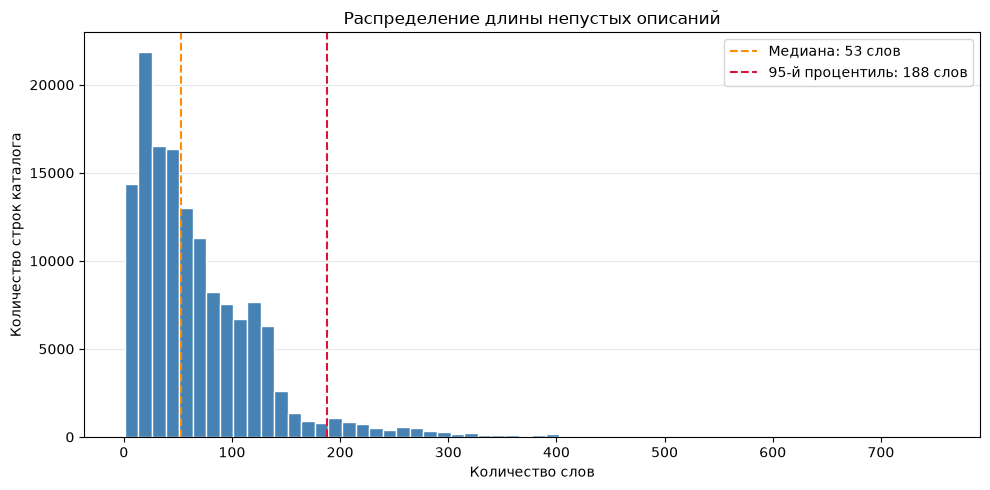

In [16]:
# Длины только непустых описаний
description_words = text_lengths.loc[
    text_lengths["description_chars"] > 0,
    "description_words",
]

median_words = description_words.median()
p95_words = description_words.quantile(0.95)

fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(
    description_words,
    bins=60,
    color="steelblue",
    edgecolor="white",
)

ax.axvline(
    median_words,
    color="darkorange",
    linestyle="--",
    label=f"Медиана: {median_words:.0f} слов",
)
ax.axvline(
    p95_words,
    color="crimson",
    linestyle="--",
    label=f"95-й процентиль: {p95_words:.0f} слов",
)

ax.set_title("Распределение длины непустых описаний")
ax.set_xlabel("Количество слов")
ax.set_ylabel("Количество строк каталога")
ax.legend()
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [17]:
# Выбираем 20 случайных уникальных карточек для ручного просмотра
sample_cards = (
    df_raw.drop_duplicates(subset="imt_id")
    .sample(n=20, random_state=SEED)
)

for number, (_, row) in enumerate(sample_cards.iterrows(), start=1):
    print(f"\n{'=' * 70}")
    print(f"Карточка {number} | imt_id: {row['imt_id']}")
    print("Название:", row["imt_name"])
    print("Корневая категория:", row["subj_root_name"])
    print("Предметная категория:", row["subj_name"])
    print("Бренд:", row["brand_name"])
    print("Цвет:", row["nm_colors_names"])
    print("Описание:", row["description"])


Карточка 1 | imt_id: 10098093
Название: Питательная маска для волос с маслом кокоса и протеинами, 60 г
Корневая категория: Красота
Предметная категория: Маски косметические
Бренд: Palmer's
Цвет: 
Описание: Интенсивная маска для питания, укрепления и восстановления сухих, поврежденных волос, обогащенная натуральным кокосовым маслом, а также маслом Моной де Таити, настоянного на лепестках цветов Тиаре.Натуральные компоненты - витамин Е, кератиновый протеин, протеины шелка и кокосовое молоко- способствуют глубокому увлажнению и питанию сухих повреждённых волос, возвращают им блеск и сияние.БЕЗ парабенов, фталатов, сульфатов и глютена

Карточка 2 | imt_id: 10149588
Название: Браслет из цветов Девичник, для девичника, для выпускного, для выступления
Корневая категория: Бижутерия
Предметная категория: Браслеты
Бренд: АксМода
Цвет: бежевый, кремовый
Описание: Браслет с цветами на руку. Основа: Атласная лента и декоративные листочки. Декор: Композиция из цветов и дополнительные элементы (ягод

### Выводы по ручному просмотру карточек
Просмотрел 20 случайных карточек. У 6 отсутствует описание,
а некоторые названия содержат только тип товара: «Ботинки», «Лонгслив».

В текстах встречаются рекламные фразы, ссылки на другие товары,
лишние пробелы, пустые кавычки и склеенные предложения.
HTML-тегов в этих 20 карточках не обнаружил.

Цвет не всегда указан в названии. Числа и латиница могут обозначать
размеры и модели, поэтому удалять их полностью нельзя.
Полезные характеристики встречаются и в конце длинных описаний.

При очистке нормализую пробелы и сохраняю характеристики товаров.
Карточки без описания, но с названием оставляю.

In [18]:
# Связь карточек с корневыми категориями
card_categories = df_raw[
    ["imt_id", "subj_root_name"]
].drop_duplicates()

# Категории товаров из тренировочной разметки
train_categories = queries_train.merge(
    card_categories,
    left_on="item_id",
    right_on="imt_id",
    how="left",
)

# Покрытие категорий тренировочной разметкой
train_coverage = (
    train_categories.groupby("subj_root_name")
    .agg(
        queries=("query_id", "nunique"),
        items=("item_id", "nunique"),
    )
    .sort_values("queries", ascending=False)
)

display(train_coverage.head(20))

,queries,items
subj_root_name,,
Одежда,489,1689
Обувь,211,596


### Решения по результатам EDA

- **Категории:** «Одежда» и «Обувь» — 36 965 и 11 524 карточки.
  К ним относятся все товары тренировочной разметки.
- **Индексация:** одна запись на imt_id, поскольку разметка
  связана с карточками, а не отдельными артикулами.
- **Дубликаты:** для каждого imt_id выбираю строку с названием,
  затем с наиболее длинным описанием. При равенстве — по nm_id.
  После этого удаляю карточки без названия и описания.
- **Пропуски:** учитываем NaN, пустые строки и пробелы.
  Товары без описания сохраняем и отмечаем has_description.
- **Варианты product_text:** название; название + категория;
  название + категория + описание.
- **Основной вариант:** название + категория + описание:
  он сохраняет тип товара и подробные характеристики.
  Пустые поля пропускаем.
- **Бренд и цвет:** пока оставляем отдельными полями.
- **Очистка:** нормализуем пробелы и переносы строк,
  сохраняем числа, размеры и обозначения моделей.
- **Длина:** необходимость обрезки проверим токенизатором
  выбранной модели.

<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> EDA получился именно таким, каким его просит задание: каждое решение из итогового списка можно проследить до конкретной ячейки выше.
<ul>
<li>Выбор категорий опирается не на «самые большие», а на проверку, где лежат размеченные товары. Это главный аргумент, и ты его нашёл.</li>
<li>На гистограмме длин отмечены медиана и 95-й перцентиль, график читается без пояснений. Мне понравилось и решение не гадать по словам, а отложить вопрос об обрезке до проверки токенизатором конкретной модели (и дальше ты это действительно сделал).</li>
<li>Выводы по ручному просмотру конкретные: склеенные предложения, пустые кавычки, рекламные фразы, числа и латиница как носители размеров и моделей. Из них потом напрямую выросла функция очистки.</li>
<li>Анализ редких категорий (четверть пар «корень — предмет» содержит 1–2 карточки) в задании не требовался, а для понимания каталога полезен.</li>
</ul>
Что можно усилить:
<ul>
<li>вывод «HTML-тегов не обнаружил» сделан по 20 карточкам. По всему каталогу это проверяется одной строкой с <code>str.contains</code> и регулярным выражением, и тогда утверждение будет опираться на 200 тысяч строк, а не на выборку;</li>
<li>покрытие категорий проверено только по train. Убедиться, что товары из test лежат в тех же двух категориях, тоже можно заранее: метки релевантности при этом не используются;</li>
<li>варианты шаблона <code>product_text</code> перечислены, но выбор основного пока сделан рассуждением. Хорошо, что на неделе 3 ты вернулся к этому вопросу и проверил его метриками.</li>
</ul>
</div>

---

## Неделя 2 — базовый пайплайн и оценка качества

**Цель:** оперевшись на результаты EDA, создать работающий поиск и получить первые метрики качества.

Прежде чем реализовывать семантический поиск, основанный на эмбеддингах, нужно проверить, как справляется более простая модель, опирающаяся на TF-IDF. Простая модель нужна как baseline, без этой точки отсчёта результат невозможно интерпретировать.


### 1. Подготовка данных


Реализуйте решения недели 1:

1. Отфильтруйте выбранные категории.
2. Дедуплицируйте строки по `imt_id`. Сформулируйте правило, по которому будете определять, какую строку оставить. К примеру, можете оставить строку с самым информативным описанием. Ответ обоснуйте.
3. Отбросьте карточки, у которых пусты одновременно и `imt_name`, и `description`.
4. Напишите функцию очистки текста.
5. Соберите единый текст карточек в отдельной колонке `product_text`.

In [19]:
# Ваш код: фильтрация, дедупликация, отсев пустых, очистка, сборка product_text
SELECTED_CATEGORIES = ["Одежда", "Обувь"]
df_products = df_raw[df_raw["subj_root_name"].isin(SELECTED_CATEGORIES)].copy()
print("Строк после отбора категорий:", len(df_products))
print("Уникальных карточек:", df_products["imt_id"].nunique())

Строк после отбора категорий: 56503
Уникальных карточек: 48489


In [20]:
df_products["_has_name"] = df_products["imt_name"].fillna("").str.strip().ne("")
df_products["_description_length"] = df_products["description"].fillna("").str.strip().str.len()
df_products = (
    df_products.sort_values(
        ["imt_id", "_has_name", "_description_length", "nm_id"],
        ascending=[True, False, False, True],
        kind="stable"
    )
    .drop_duplicates(subset="imt_id", keep="first")
    .drop(columns=["_has_name", "_description_length"])
    .reset_index(drop=True)
)
print("Строк после дедупликации:", len(df_products))
print("Повторов imt_id:", df_products["imt_id"].duplicated().sum())

Строк после дедупликации: 48489
Повторов imt_id: 0


In [21]:
empty_text = (
    df_products["imt_name"].fillna("").str.strip().eq("")
    & df_products["description"].fillna("").str.strip().eq("")
)
print("Исключено карточек без текста:", empty_text.sum())
df_products = df_products.loc[~empty_text].copy().reset_index(drop=True)
df_products["has_description"] = df_products["description"].fillna("").str.strip().ne("")
print("Осталось карточек:", len(df_products))

Исключено карточек без текста: 113
Осталось карточек: 48376


In [22]:
import re
import html
def clean_text(value):
    if pd.isna(value):
        return ""
    text = html.unescape(str(value))
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"[\u200b-\u200d\ufeff]", "", text)
    text = re.sub(r"[\x00-\x1f\x7f]", " ", text)
    text = re.sub(r"(?<=[а-яёА-ЯЁ])\.(?=[А-ЯЁ])", ". ", text)
    text = text.replace('""', "")
    return re.sub(r"\s+", " ", text).strip()
for column in ["imt_name", "subj_name", "description"]:
    df_products[column] = df_products[column].map(clean_text)
df_products["has_description"] = df_products["description"].ne("")
display(df_products[["imt_name", "subj_name", "description"]].head())

,imt_name,subj_name,description
0,Платье,Платья,
1,Куртка,Куртки,
2,Сандалии,Сандалии,
3,Ботинки,Ботинки,
4,Сандалии,Сандалии,


In [23]:
text_columns = ["imt_name", "subj_name", "description"]
df_products["product_text"] = df_products[text_columns].apply(
    lambda row: "\n".join(value for value in row if value),
    axis=1
)
print("Пустых product_text:", df_products["product_text"].str.strip().eq("").sum())
for _, row in df_products.sample(n=5, random_state=SEED).iterrows():
    print(f"\nimt_id: {row['imt_id']}")
    print(row["product_text"])

Пустых product_text: 0

imt_id: 10178223
Атласная женская блузка
Рубашки
Атласная блузка красивого табачного цвета с длинными широкими рукавами. Элегантная модель, которая соберет на себе все взгляды.

imt_id: 1008592
Толстовка
Толстовки

imt_id: 10154123
Босоножки
Босоножки

imt_id: 10183931
Сандалии
Сандалии

imt_id: 10012374
Сабо открытые пантолеты натуральная кожа на низкой подошве
Сабо
ПОЖАЛУЙСТА, пишите Ваши отзывы и замечания, нам это Важно и Вашу помощь оценят другие покупатели (+ к карме)))! Все наши женские ботинки, кроссовки, сабо, босоножки и туфли выполнены из натуральной кожи, натуральной замши и натурального меха (зимние) по лекалам итальянских дизайнеров, на производстве в Турции. Колодки адаптированы нашими технологами под российские стандарты и особенности стопы. Мы очень стараемся создавать удобные, красивые, яркие, трендовые модели из самых качественных материалов и делать их удобными и комфортными и Ваша помощь станет неоценимой! Лёгкие открытые сабо из натуральной

<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Подготовка данных сделана чисто.
<ul>
<li>Дедупликация через <code>sort_values</code> + <code>drop_duplicates</code> работает быстро, а <code>nm_id</code> последним ключом сортировки делает выбор строки детерминированным даже при равной длине описания. Правило «сначала строка с названием, потом с самым длинным описанием» согласовано с шаблоном текста: описание в него входит.</li>
<li>Отсеиваются только карточки совсем без текста, товары без описания остаются. Это правильно: по названию и категории их всё ещё можно найти.</li>
<li>Каждое правило в <code>clean_text</code> отвечает на находку из ручного просмотра: склеенные предложения, пустые кавычки, невидимые символы. Числа и латиница сохранены. Отдельный плюс за то, что запрос потом проходит через ту же функцию.</li>
<li>В <code>product_text</code> есть явный разделитель, пустые поля пропускаются, есть контроль пустых текстов.</li>
</ul>
Идеи для развития:
<ul>
<li>в примере после очистки попались пять карточек без описания, поэтому работу функции не видно. Нагляднее взять несколько строк с описанием и показать их до и после;</li>
<li>как альтернативу выбору одной строки можно агрегировать варианты: название и описание взять из лучшей строки, а цвета собрать со всех <code>nm_id</code> карточки. Сейчас цвета остальных артикулов теряются, и ниже, в разборе ошибок, ты сам упрёшься в запрос «бежевые футболки». Получится готовая гипотеза для эксперимента;</li>
<li>рекламные вставки («пишите ваши отзывы...», «нас ищут: ...») ты заметил, но оставил. Это допустимое решение, только его стоит проговорить явно.</li>
</ul>
</div>

### Каталог для поиска и оценки

1. Посчитайте метрику при поиске по всему отфильтрованному каталогу. Например, вычислите NDCG@10 лексическим поиском на 100 запросах.
2. Выведите топ-10 для одного запроса и отметьте, какие товары есть в разметке, а каких нет. Выясните, в чём проблема.
3. Ограничьте каталог оценки пулом асессоров: возьмите из `wb_products_dedup.parquet` только список `imt_id` и оставьте в своём подготовленном каталоге пересечение с ним. Тексты и все признаки — ваши, из шага 1.
4. Пересчитайте метрику и сравните результаты.
5. Посмотрите на распределение `relevance` и число оценённых товаров на запрос. Проверьте, у всех ли запросов есть товары с `relevance` ≥ 2.

In [24]:
from sklearn.feature_extraction.text import TfidfVectorizer
full_catalog = df_products.copy().reset_index(drop=True)
full_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=100000,
    lowercase=True,
    norm="l2",
    dtype=np.float32
)
full_tfidf = full_vectorizer.fit_transform(full_catalog["product_text"])
print("Размер матрицы TF-IDF:", full_tfidf.shape)

Размер матрицы TF-IDF: (48376, 100000)


In [25]:
def search_lexical_full(query, top_k=10):
    if top_k < 1:
        raise ValueError("top_k должен быть положительным")
    query_vector = full_vectorizer.transform([clean_text(query)])
    scores = (full_tfidf @ query_vector.T).toarray().ravel()
    top_indices = np.argsort(-scores, kind="stable")[:top_k]
    result = full_catalog.iloc[top_indices][
        ["imt_id", "imt_name", "subj_name"]
    ].copy()
    result["score"] = scores[top_indices]
    return result.reset_index(drop=True)
example_query = queries_train["query_text"].iloc[0]
# print("Запрос:", example_query)
# display(search_lexical_full(example_query))

example_query_id = queries_train["query_id"].iloc[0]
example_labels = queries_train.loc[
    queries_train["query_id"].eq(example_query_id),
    ["item_id", "relevance"]
]
example_results = search_lexical_full(example_query).merge(
    example_labels,
    left_on="imt_id",
    right_on="item_id",
    how="left",
    validate="one_to_one"
).drop(columns="item_id")
example_results["is_assessed"] = example_results["relevance"].notna()
display(example_results)
print("Оценённых товаров в топ-10:", example_results["is_assessed"].sum())

,imt_id,imt_name,subj_name,score,relevance,is_assessed
0,1018103,Жилеты,Жилеты,0.44404,NaN,False
1,10002776,Жилеты,Жилеты,0.44404,NaN,False
2,10002778,Жилеты,Жилеты,0.44404,NaN,False
3,10031391,Жилеты,Жилеты,0.44404,NaN,False
4,10076189,Жилеты,Жилеты,0.44404,1.0,True
5,10076190,Жилеты,Жилеты,0.44404,NaN,False
6,10089945,Жилеты,Жилеты,0.44404,NaN,False
7,10089962,Жилеты,Жилеты,0.44404,NaN,False
8,10114374,Жилеты,Жилеты,0.44404,NaN,False
9,10114375,Жилеты,Жилеты,0.44404,NaN,False


Оценённых товаров в топ-10: 1


In [26]:
def ndcg_at_k(item_ids, relevance_map, k=10):
    relevance = np.array([relevance_map.get(item_id, 0) for item_id in item_ids[:k]])
    ideal = np.array(sorted(relevance_map.values(), reverse=True)[:k])
    dcg = np.sum((2.0**relevance - 1) / np.log2(np.arange(len(relevance)) + 2))
    idcg = np.sum((2.0**ideal - 1) / np.log2(np.arange(len(ideal)) + 2))
    return float(dcg / idcg) if idcg > 0 else 0.0
eval_queries = (
    queries_train[["query_id", "query_text"]]
    .drop_duplicates()
    .sample(n=100, random_state=SEED)
)
relevance_maps = {
    query_id: group.set_index("item_id")["relevance"].to_dict()
    for query_id, group in queries_train.groupby("query_id")
}
full_ndcg_scores = []
for row in eval_queries.itertuples(index=False):
    item_ids = search_lexical_full(row.query_text, top_k=10)["imt_id"].tolist()
    full_ndcg_scores.append(ndcg_at_k(item_ids, relevance_maps[row.query_id], k=10))
print("Запросов:", len(full_ndcg_scores))
print("NDCG@10 по полному каталогу:", round(np.mean(full_ndcg_scores), 4))

Запросов: 100
NDCG@10 по полному каталогу: 0.072


In [27]:
if not ASSESSED_POOL_PATH.exists():
    s3.download_file(source_bucket, ASSESSED_POOL_PATH.name, str(ASSESSED_POOL_PATH))
assessed_ids = pd.read_parquet(ASSESSED_POOL_PATH, columns=["imt_id"])["imt_id"]
eval_catalog = full_catalog[
    full_catalog["imt_id"].isin(assessed_ids)
].copy().reset_index(drop=True)
print("Карточек в исходном пуле:", assessed_ids.nunique())
print("Карточек в каталоге оценки:", len(eval_catalog))
print(
    "Товаров train вне каталога оценки:",
    len(set(queries_train["item_id"]) - set(eval_catalog["imt_id"]))
)

Карточек в исходном пуле: 4256
Карточек в каталоге оценки: 4256
Товаров train вне каталога оценки: 0


In [28]:
eval_mask = full_catalog["imt_id"].isin(assessed_ids).to_numpy()
eval_tfidf = full_tfidf[eval_mask]
def search_lexical(query, top_k=10):
    if top_k < 1:
        raise ValueError("top_k должен быть положительным")
    query_vector = full_vectorizer.transform([clean_text(query)])
    scores = (eval_tfidf @ query_vector.T).toarray().ravel()
    top_indices = np.argsort(-scores, kind="stable")[:top_k]
    result = eval_catalog.iloc[top_indices][
        ["imt_id", "imt_name", "subj_name"]
    ].copy()
    result["score"] = scores[top_indices]
    return result.reset_index(drop=True)
eval_ndcg_scores = []
for row in eval_queries.itertuples(index=False):
    item_ids = search_lexical(row.query_text, top_k=10)["imt_id"].tolist()
    eval_ndcg_scores.append(ndcg_at_k(item_ids, relevance_maps[row.query_id], k=10))
display(pd.DataFrame({
    "Каталог": ["Полный", "Пул оценки"],
    "Карточек": [len(full_catalog), len(eval_catalog)],
    "NDCG@10": [np.mean(full_ndcg_scores), np.mean(eval_ndcg_scores)]
}))

,Каталог,Карточек,NDCG@10
0,Полный,48376,0.072021
1,Пул оценки,4256,0.463402


In [29]:
RELEVANCE_THRESHOLD = 2
print("Распределение оценок:")
display(
    queries_train["relevance"].value_counts().sort_index()
    .rename_axis("relevance").to_frame("Количество")
)
items_per_query = queries_train.groupby("query_id")["item_id"].nunique()
print("Оценённых товаров на запрос:")
display(items_per_query.describe().round(2))
relevant_per_query = (
    queries_train.assign(is_relevant=queries_train["relevance"] >= RELEVANCE_THRESHOLD)
    .groupby("query_id")["is_relevant"].sum()
)
print("Запросов без товаров с relevance >= 2:", relevant_per_query.eq(0).sum())

Распределение оценок:


,Количество
relevance,
1,9652
2,1101
3,700


Оценённых товаров на запрос:


count    700.00
mean      16.36
std        5.42
min        1.00
25%       14.00
50%       16.00
75%       19.00
max       31.00
Name: item_id, dtype: float64

Запросов без товаров с relevance >= 2: 0


<div class="alert alert-warning">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Небольшие замечания и рекомендации💡:</b> По коду раздел выполнен полностью и хорошо: метрика на полном каталоге, топ-10 с пометкой <code>is_assessed</code>, пересчёт на пуле, распределение оценок, проверка запросов без релевантных товаров. Приятно, что TF-IDF не переобучается заново, а матрица просто фильтруется маской, и что есть проверка «все товары train остались в каталоге оценки».

Чего не хватает, так это выводов текстом. Раздел существует ради вопроса «в чём проблема?», а в ноутбуке сейчас только числа:
<ul>
<li>NDCG@10 вырос с 0.07 до 0.46 при смене каталога, хотя модель осталась той же. Почему? Что на самом деле измеряла первая цифра? Таблица с жилетами у тебя уже есть, осталось её прокомментировать;</li>
<li>посмотри внимательно на распределение <code>relevance</code>: 700 оценок «3» на 700 запросов, а нулей в разметке нет совсем. Что это говорит о том, как устроена разметка, и как это связано с выбором порога бинаризации ниже?</li>
<li>минимум оценённых товаров на запрос равен 1. Стоит посмотреть, сколько таких запросов: на них Recall и NDCG ведут себя вырожденно.</li>
</ul>
И ещё одно наблюдение по той же таблице: у всех десяти жилетов одинаковый скор 0.444. При равных скорах порядок задаёт позиция строки в каталоге, то есть в топ попадают товары с меньшим индексом, а не более подходящие. Я прикинул у себя: такие совпадения в топ-10 есть примерно у трети запросов. На средних метриках это сказывается слабо, но при разборе отдельных запросов об этом полезно помнить.

Добавь, пожалуйста, короткую Markdown-ячейку с выводами.
</div>

In [30]:
items_per_query = queries_train.groupby("query_id")["item_id"].nunique()
print("Запросов с одним оценённым товаром:", items_per_query.eq(1).sum())
print("Доля таких запросов, %:", round(items_per_query.eq(1).mean() * 100, 2))
top_relevance_per_query = (
    queries_train["relevance"].eq(3)
    .groupby(queries_train["query_id"]).sum()
)
print("Запросов ровно с одной оценкой 3:", top_relevance_per_query.eq(1).sum())
for threshold in [1, 2, 3]:
    relevant_per_query = (
        queries_train["relevance"].ge(threshold)
        .groupby(queries_train["query_id"]).sum()
    )
    print(f"Порог {threshold}: в среднем {relevant_per_query.mean():.2f} релевантных товаров на запрос")

Запросов с одним оценённым товаром: 4
Доля таких запросов, %: 0.57
Запросов ровно с одной оценкой 3: 700
Порог 1: в среднем 16.36 релевантных товаров на запрос
Порог 2: в среднем 2.57 релевантных товаров на запрос
Порог 3: в среднем 1.00 релевантных товаров на запрос


<div class="alert alert-info">
<b>Выводы </b>

<p>NDCG@10 вырос с 0,0720 до 0,4634 из-за сокращения каталога, а не улучшения модели. В полном каталоге поиск находил товары без разметки, которые получали 0 при оценке. Например, среди десяти жилетов оценён только один. Поэтому исходная метрика зависела и от качества поиска, и от покрытия разметки.</p>

<p>У каждого запроса ровно один товар с оценкой 3, нулевых оценок нет, большинство оценок — 1. Это похоже на подбор товаров вокруг одного целевого примера. При пороге 1 релевантными считаются все размеченные товары — в среднем 16,36 на запрос. При пороге 3 остаётся только один. Выбираю порог 2: он учитывает подходящие товары, исключая слабые совпадения. В среднем их 2,57 на запрос. Для NDCG использую всю шкалу оценок.</p>

<p>У 4 запросов (0,57%) размечен только один товар. Для них Recall показывает лишь попадание этого товара в топ-K, а NDCG — ещё и его позицию. Остальные результаты выдачи так оценить нельзя.</p>

<p>У десяти жилетов одинаковый скор. Их порядок определяется порядком строк каталога, а не тем, какой товар лучше подходит запросу. Это нужно учитывать при разборе выдачи.</p>
</div>

### 2. Модели поиска

Реализуйте два поисковых движка с одинаковым интерфейсом. Это позволит прогнать оба через одну функцию оценки:

In [31]:
def search_xxx(query: str, top_k: int = 10) -> pd.DataFrame:
    """Возвращает top_k товаров с колонками imt_id, imt_name, subj_name, score."""


Реализуйте лексический baseline на TF-IDF:

In [32]:
# Ваш код: TF-IDF-индекс и search_lexical
# Индекс и функция реализованы выше для сравнения каталогов.
display(search_lexical(example_query, top_k=5))

,imt_id,imt_name,subj_name,score
0,10076189,Жилеты,Жилеты,0.444040
1,1016032,Жилет PHILOMENE,Жилеты,0.389681
2,10001023,Жилет Юнона,Жилеты,0.389681
3,1000988,Жилет,Жилеты,0.310180
4,10077041,"Платье вечернее ""Jennifer""/Летний сарафан/Бело...",Платья,0.307311


Реализуйте семантический поиск:

In [33]:
# Ваш код: эмбеддинги и search_semantic
from sentence_transformers import SentenceTransformer
MODEL_NAME = "intfloat/multilingual-e5-small"
model = SentenceTransformer(MODEL_NAME, device="cpu")
print("Модель:", MODEL_NAME)
print("Лимит токенов:", model.max_seq_length)
print("Размерность вектора:", model.get_embedding_dimension())

c:\Users\Lenovo\airflowtemplateproject\semantic-search-project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1264.59it/s]


Модель: intfloat/multilingual-e5-small
Лимит токенов: 512
Размерность вектора: 384


In [34]:
passages = ["passage: " + text for text in eval_catalog["product_text"]]
token_lengths = []
for start in range(0, len(passages), 64):
    encoded = model.tokenizer(
        passages[start:start + 64],
        truncation=False,
        padding=False,
        return_length=True
    )
    token_lengths.extend(encoded["length"])
token_lengths = np.array(token_lengths)
print("Карточек:", len(token_lengths))
print("Максимальная длина в токенах:", token_lengths.max())
print("Превышают лимит:", (token_lengths > model.max_seq_length).sum())
print("Доля превышающих лимит, %:", round(
    (token_lengths > model.max_seq_length).mean() * 100, 2
))

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (548 > 512). Running this sequence through the model will result in indexing errors


Карточек: 4256
Максимальная длина в токенах: 1134
Превышают лимит: 53
Доля превышающих лимит, %: 1.25


In [35]:
model.max_seq_length = 512
product_embeddings = model.encode(
    passages,
    batch_size=16,
    normalize_embeddings=True,
    convert_to_numpy=True,
    show_progress_bar=True
)
ARTIFACTS_DIR = Path("artifacts")
ARTIFACTS_DIR.mkdir(exist_ok=True)
np.save(ARTIFACTS_DIR / "product_embeddings_e5_small.npy", product_embeddings)
np.save(ARTIFACTS_DIR / "product_ids_e5_small.npy", eval_catalog["imt_id"].to_numpy())
print("Размер матрицы эмбеддингов:", product_embeddings.shape)

Batches:   0%|          | 0/266 [00:00<?, ?it/s]

Batches: 100%|██████████| 266/266 [05:15<00:00,  1.19s/it]


Размер матрицы эмбеддингов: (4256, 384)


In [ ]:
def make_semantic_search(embeddings, catalog):
    if len(embeddings) != len(catalog):
        raise ValueError("Количество векторов и строк каталога не совпадает")

    def search(query, top_k=10):
        if top_k < 1:
            raise ValueError("top_k должен быть положительным")

        query_embedding = model.encode(
            "query: " + clean_text(query),
            normalize_embeddings=True,
            convert_to_numpy=True,
            show_progress_bar=False
        )

        scores = embeddings @ query_embedding
        top_indices = np.argsort(-scores, kind="stable")[:top_k]

        result = catalog.iloc[top_indices][
            ["imt_id", "imt_name", "subj_name"]
        ].copy()
        result["score"] = scores[top_indices]

        return result.reset_index(drop=True)

    return search


search_semantic = make_semantic_search(
    product_embeddings,
    eval_catalog
)

print("Запрос:", example_query)
display(search_semantic(example_query))

Запрос: жилеты на пуговицах


,imt_id,imt_name,subj_name,score
0,10096636,Жилет для девочки,Жилеты,0.856990
1,10092580,Атласное платье на пуговичках,Платья,0.855234
2,100433,Жилетка,Жилеты,0.853219
3,10089060,Жилет утепленный,Жилеты,0.851672
4,10086438,Жилеты,Жилеты,0.850883
5,10136994,Пиджак женский,Жакеты,0.849808
6,10088082,Куртка джинсовая,Пиджаки,0.849802
7,10088093,Худи укороченое без рукавов,Худи,0.848963
8,10028340,Жилет,Жилеты,0.846742
9,1016032,Жилет PHILOMENE,Жилеты,0.846488


Прогоните 3–5 запросов вручную и сравните выдачу обоих подходов. Это самый простой способ поймать грубые ошибки до подсчёта метрик.

In [37]:
# Ваш код
sample_queries = (
    queries_train[["query_id", "query_text"]]
    .drop_duplicates()
    .sample(n=3, random_state=SEED)
)
for row in sample_queries.itertuples(index=False):
    print("\nЗапрос:", row.query_text)
    for method_name, search_function in [
        ("Лексический поиск", search_lexical),
        ("Семантический поиск", search_semantic)
    ]:
        result = search_function(row.query_text, top_k=5)
        result["relevance"] = result["imt_id"].map(relevance_maps[row.query_id])
        print(method_name)
        display(result)


Запрос: топы cop copine
Лексический поиск


,imt_id,imt_name,subj_name,score,relevance
0,10016977,Топы,Топы,0.766925,1
1,10047446,Топ - TROPICO,Топы,0.722997,1
2,10150664,Топ - CINTIA,Топы,0.722997,1
3,101146,Топ,Топы,0.561121,1
4,10002416,Майка Сердце,Топы,0.456532,1


Семантический поиск


,imt_id,imt_name,subj_name,score,relevance
0,10150664,Топ - CINTIA,Топы,0.874794,1.0
1,10002416,Майка Сердце,Топы,0.870075,1.0
2,10042858,Майка,Топы,0.865414,1.0
3,10047446,Топ - TROPICO,Топы,0.864523,1.0
4,10034209,Куртка,Кофты,0.863276,NaN



Запрос: худи mego as
Лексический поиск


,imt_id,imt_name,subj_name,score,relevance
0,1004435,Худи,Худи,0.865283,1
1,10142636,Худи Raava,Худи,0.731015,1
2,10089828,Худи UFC,Худи,0.717322,1
3,10080294,Худи Oversize,Худи,0.592081,1
4,10088093,Худи укороченое без рукавов,Худи,0.524681,1


... (2 outputs left out)


Запрос: бриджи зуавы
Лексический поиск


,imt_id,imt_name,subj_name,score,relevance
0,1003861,Бриджи,Бриджи,0.470974,1
1,10124357,Бриджи Тропики,Бриджи,0.347153,1
2,10000043,Бриджи/большие размеры/стрейч/ажур,Бриджи,0.323375,1
3,10005760,Бриджи женские/большого размера/Облегающие брю...,Бриджи,0.228958,1
4,10127189,Бриджи детские,Брюки,0.213279,1


Семантический поиск


,imt_id,imt_name,subj_name,score,relevance
0,10127189,Бриджи детские,Брюки,0.869414,1.0
1,10046070,Бриджи женские,Капри,0.863046,1.0
2,10096870,Зуавы,Бриджи,0.859113,3.0
3,10090353,Кардиган ZOJA,Кардиганы,0.857642,NaN
4,10090874,Брюки SOVA LINA,Брюки,0.854272,NaN


<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Семантический поиск реализован грамотно, и в нём есть несколько деталей, которые показывают, что документацию модели ты прочитал:
<ul>
<li>префиксы <code>query: </code> и <code>passage: </code> для E5. Без них модель работает заметно хуже, и про них очень часто забывают;</li>
<li>длина текстов измерена токенизатором самой модели: лимит превышают 1.25% карточек. Это и есть обещанный в EDA ответ на вопрос об обрезке, причём измеренный, а не оценённый на глаз;</li>
<li>эмбеддинги нормированы, поэтому скалярное произведение равно косинусу; товары кодируются батчами; вместе с матрицей сохраняется порядок <code>imt_id</code>.</li>
</ul>
Интерфейс у обеих функций одинаковый, есть проверка аргумента <code>top_k</code>, запросы для ручного сравнения взяты из разметки, и выдача сразу сверена с оценками.

💡 Что стоит добавить:
<ul>
<li><b>обоснование выбора модели.</b> Почему именно <code>multilingual-e5-small</code>? Аргументы у тебя наверняка есть (русский язык, окно в 512 токенов, скорость на CPU), их нужно записать. Выбор модели без объяснения выглядит случайным, даже когда он удачный;</li>
<li>эмбеддинги сохраняются на диск, но обратно нигде не читаются, и при перезапуске ноутбука каждый расчёт снова займёт 4–6 минут. Проверка «файл есть и порядок <code>imt_id</code> совпадает → загрузить» превратит сохранение в настоящий кэш;</li>
<li>при оценке запросы кодируются по одному внутри цикла. Быстрее один раз закодировать все 700 запросов батчем и перемножить матрицы;</li>
<li>три случайных запроса дали два брендовых и ни одного описательного («на пуговицах», «с карманами», цвет). Можно добрать пару запросов вручную, чтобы увидеть разные типы.</li>
</ul>
</div>

### 3. Оценка качества решений

Реализуйте метрики Precision@K, Recall@K, MRR, NDCG@K, HitRate@K.

Три ключевые особенности, которые надо учесть при расчёте:

1. Порог бинаризации. Precision@K, Recall@K, MRR, HitRate@K бинарны, а шкала `relevance` — от `0` до `3`. С какой оценки товар считается релевантным? Вынесите порог в параметр, а не константу внутри функции.
2. NDCG считайте по полной шкале 0–3 (`gain = 2^rel - 1`), а не по бинаризованной, иначе теряется смысл градуированной разметки.
3. Неразмеченные товары в выдаче трактуйте как нерелевантные (`relevance_map.get(item_id, 0)`).

Выводы запишите в Markdown-ячейке и рабочем файле Markdown.

In [38]:
RELEVANCE_THRESHOLD = 2   # Ваше решение, его нужно обосновать

# Ваш код для работы с метриками
def calculate_metrics(item_ids, relevance_map, k, threshold=2):
    top_ids = item_ids[:k]
    hits = np.array([
        relevance_map.get(item_id, 0) >= threshold
        for item_id in top_ids
    ], dtype=bool)
    total_relevant = sum(rel >= threshold for rel in relevance_map.values())
    positions = np.flatnonzero(hits)
    return {
        f"Precision@{k}": hits.sum() / k,
        f"Recall@{k}": hits.sum() / total_relevant if total_relevant else 0.0,
        f"MRR@{k}": 1.0 / (positions[0] + 1) if len(positions) else 0.0,
        f"NDCG@{k}": ndcg_at_k(item_ids, relevance_map, k),
        f"HitRate@{k}": float(hits.any())
    }
display(pd.Series(calculate_metrics(
    [10, 20, 30],
    {10: 0, 20: 3, 30: 2, 40: 2},
    k=3,
    threshold=RELEVANCE_THRESHOLD
)))

Precision@3    0.666667
Recall@3       0.666667
MRR@3          0.500000
NDCG@3         0.569290
HitRate@3      1.000000
dtype: float64

In [39]:
K_VALUES = [1, 3, 5, 10]
evaluation_queries = queries_train[["query_id", "query_text"]].drop_duplicates()
metrics_rows = []
for row in evaluation_queries.itertuples(index=False):
    for method, search_function in [
        ("TF-IDF", search_lexical),
        ("E5-small", search_semantic)
    ]:
        item_ids = search_function(row.query_text, top_k=max(K_VALUES))["imt_id"].tolist()
        result = {"method": method, "query_id": row.query_id}
        for k in K_VALUES:
            result.update(calculate_metrics(
                item_ids,
                relevance_maps[row.query_id],
                k=k,
                threshold=RELEVANCE_THRESHOLD
            ))
        metrics_rows.append(result)
metrics_by_query = pd.DataFrame(metrics_rows)
metrics_summary = metrics_by_query.groupby("method").mean(numeric_only=True)

In [40]:
metric_order = [
    f"{metric}@{k}"
    for metric in ["Precision", "Recall", "MRR", "NDCG", "HitRate"]
    for k in K_VALUES
]
display(metrics_summary[metric_order].round(4).T)

method,E5-small,TF-IDF
Precision@1,0.3871,0.0729
Precision@3,0.2881,0.0748
Precision@5,0.2246,0.0777
Precision@10,0.1507,0.0759
Recall@1,0.2213,0.0391
Recall@3,0.4104,0.1051
Recall@5,0.4907,0.1745
Recall@10,0.5942,0.3137
MRR@1,0.3871,0.0729
MRR@3,0.4807,0.1186


### Выводы по первой итерации
Сравнил TF-IDF и E5-small на 700 тренировочных запросах и каталоге из 4256 карточек. Для бинарных метрик выбрал порог 2: учитываю подходящие товары с оценками 2 и 3, исключая слабые совпадения. Для NDCG использую всю шкалу 0–3.

E5-small оказался лучше по всем рассчитанным метрикам. NDCG@10 составил 0,4741 против 0,4364 у TF-IDF, Recall@10 — 0,5942 против 0,3137. Особенно заметна разница на первой позиции: Precision@1 — 0,3871 против 0,0729.

При этом NDCG@10 у TF-IDF сравнительно высокий: метрика учитывает десять позиций и даёт положительный вклад даже товарам с оценкой 1. Для Precision и Recall такие товары нерелевантны. Поэтому оцениваю методы по нескольким метрикам.

В просмотренных примерах оба метода плохо справились с брендовыми запросами. E5-small нашёл «Зуавы» на третьем месте, но иногда возвращал товары другой категории. Далее проверю добавление бренда, изменение состава product_text и гибридный поиск.

Оценка ограничена синтетической разметкой и пулом карточек. Неразмеченные товары получают 0, хотя могут подходить запросу. На этом этапе тестовую выборку для расчёта метрик и настройки не использовал.

<div class="alert alert-warning">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Небольшие замечания и рекомендации💡:</b> Метрики реализованы правильно, придраться не к чему: порог вынесен в параметр, неразмеченные товары получают 0, NDCG считается по полной шкале с <code>gain = 2^rel − 1</code>, а идеальная выдача строится по всей разметке запроса, а не по найденному. Precision делится на <code>k</code>, а не на длину выдачи. Очень понравилась проверка на игрушечном примере: я пересчитал руками, все пять значений сходятся. Такой мини-тест стоит оставлять всегда.

Вывод по первой итерации честный: ты сам указал, что оценка ограничена синтетикой и пулом, и не трогал test.

Что нужно доработать:
<ul>
<li>в коде остался комментарий «Ваше решение, его нужно обосновать», а обоснования порога нет. Почему 2, а не 1 или 3? Подсказка лежит в распределении оценок из предыдущего раздела: прикинь, сколько релевантных товаров на запрос получится при каждом из трёх порогов;</li>
<li>в таблице есть интересная пара чисел, которую ты не прокомментировал: у TF-IDF Precision@1 = 0.07, а NDCG@10 = 0.44, почти как у E5. Откуда лексический поиск набирает NDCG, если релевантных товаров наверху почти нет? Ответ хорошо объясняет, почему для этой задачи нельзя смотреть на одну метрику;</li>
<li>таблицу удобнее читать, когда строки сгруппированы по метрике (все Precision подряд, все Recall подряд): так сразу видно поведение по K.</li>
</ul>
</div>

---

## Неделя 3 — эксперименты, дообучение и MLflow

**Цель:** проверить гипотезы о том, как можно улучшить систему поиска, зафиксировать эксперименты, дать рекомендации бизнесу.

**Главное правило:** «один эксперимент — одна гипотеза — одно изменение». Если поменять сразу модель, шаблон текста и параметры векторизации, прирост будет невозможно объяснить и повторить.

### 1. Эксперименты по улучшению

Проведите минимум три эксперимента. Оформляйте каждый по схеме:

- **Гипотеза** — ваше предположение и его обоснование. Причины «хочу попробовать другую модель» недостаточно, нужны объяснения такого типа: «Модель с большим окном улучшит поиск товаров с длинными описаниями, потому что в EDA я видел, что X% описаний обрезаются по лимиту токенов».
- **Что меняется** — ровно один компонент относительно baseline.
- **Результат** — метрики на тех же данных, с тем же порогом и теми же K.
- **Вывод** — принимаем или отклоняем гипотезу. Что это говорит о данных?

Придумывайте гипотезы, опираясь на ошибки, которые обнаружили на неделе 2. Если выбранная модель путает смежные категории, попробуйте проверить, решит ли проблему добавление данных из `subj_name` в общий текст карточки. Другой пример: если лексический поиск обходит семантический на точных названиях, а семантический выигрывает у лексического, когда дело доходит до неточных формулировок, — это повод попробовать реализовать гибридный поиск.

Направления для разработки гипотез:

- изменить шаблон `product_text`;
- попробовать другую модель эмбеддингов;
- дообучить модели;
- реализовать гибридный поиск с помощью взвешенной суммы скоров или реранкинга семантикой поверх лексического отбора;
- ввести лемматизацию и стоп-слова для TF-IDF;
- изменить параметры векторизации.

In [41]:
# Эксперимент 1
# Гипотеза: добавление бренда улучшит поиск по запросам с названием бренда.
# Что меняем: добавляем brand_name в product_text, остальные настройки сохраняем.

# Ваш код
eval_catalog_brand = eval_catalog.copy()
eval_catalog_brand["brand_name"] = eval_catalog_brand["brand_name"].map(clean_text)
eval_catalog_brand["product_text"] = eval_catalog_brand.apply(
    lambda row: "\n".join(
        value for value in [
            row["imt_name"], row["subj_name"], row["brand_name"], row["description"]
        ] if value
    ),
    axis=1
)
for _, row in eval_catalog_brand.sample(n=3, random_state=SEED).iterrows():
    print(f"\nimt_id: {row['imt_id']}")
    print(row["product_text"])


imt_id: 1008644
халат
Халаты банные
Taubert

imt_id: 10026742
Рубашка на кнопках
Рубашки
CHMELAN
Рубашка свободного кроя. Два накладных кармана с клапаном. Кнопки серебристого цвета. Рукав регулируется шлевкой на кнопочке.

imt_id: 10116692
Ночная сорочка для девочки Детская
Ночные сорочки
Alena Alenkina
Трикотажная ночная сорочка для девочек с коротким рукавом - комфортная детская одежда для сна. Ночнушка из 100% хлопка, ткань кулирка. Ночная рубашка с ярким принтом отлично подойдет для дома и отдыха, дачи и детского садика, как легкое платье на лето и модная пижама для девочки. Сорочка приятная к телу, идеально для комфортного сна ребенка и как домашняя одежда. Маленькая модница оценит подарок в виде яркой пижамы на любой праздник: 8 марта, День рождение, новый год. Сорочки на возраст 6, 7, 8, 9, 10, 11, 12, 13, 14 лет. На рост 104 110 116 122 128 134 140 146 152 158 164. В каталоге нашего бренда Alena Alenkina (Алена Аленкина) представлена летняя и домашняя детская одежда для девоч

In [42]:
passages_brand = ["passage: " + text for text in eval_catalog_brand["product_text"]]
product_embeddings_brand = model.encode(
    passages_brand,
    batch_size=16,
    normalize_embeddings=True,
    convert_to_numpy=True,
    show_progress_bar=True
)
ARTIFACTS_DIR.mkdir(exist_ok=True)
np.save(ARTIFACTS_DIR / "product_embeddings_e5_brand.npy", product_embeddings_brand)
np.save(ARTIFACTS_DIR / "product_ids_e5_brand.npy", eval_catalog_brand["imt_id"].to_numpy())
print("Размер матрицы:", product_embeddings_brand.shape)

Batches: 100%|██████████| 266/266 [04:35<00:00,  1.04s/it]

Размер матрицы: (4256, 384)


In [75]:
def evaluate(search_fn, queries, relevance_maps, name):
    rows = []
    for row in queries.itertuples(index=False):
        item_ids = search_fn(row.query_text, top_k=max(K_VALUES))["imt_id"].tolist()
        result = {"method": name, "query_id": row.query_id}
        for k in K_VALUES:
            result.update(calculate_metrics(
                item_ids,
                relevance_maps[row.query_id],
                k=k,
                threshold=RELEVANCE_THRESHOLD
            ))
        rows.append(result)
    return pd.DataFrame(rows)
search_semantic_brand = make_semantic_search(
    product_embeddings_brand, eval_catalog_brand
)
metrics_by_query_brand = evaluate(
    search_semantic_brand, evaluation_queries, relevance_maps, "E5-small + brand"
)
metrics_summary_brand = metrics_by_query_brand.groupby("method")[metric_order].mean()
display(pd.concat([
    metrics_summary.loc[["E5-small"]],
    metrics_summary_brand
])[metric_order].round(4).T)

method,E5-small,E5-small + brand
Precision@1,0.3871,0.5743
Precision@3,0.2881,0.3600
Precision@5,0.2246,0.2711
Precision@10,0.1507,0.1713
Recall@1,0.2213,0.3753
Recall@3,0.4104,0.5877
Recall@5,0.4907,0.6776
Recall@10,0.5942,0.7674
MRR@1,0.3871,0.5743
MRR@3,0.4807,0.6662


**Вывод по эксперименту 1.**
Добавление бренда улучшило качество поиска: NDCG@10 вырос
с 0,4741 до 0,5633, а Recall@10 — с 0,5942 до 0,7674.
Доля запросов с релевантным товаром на первом месте увеличилась
с 38,71% до 57,43%. Гипотеза подтверждается на тренировочном
наборе. Отдельно проверил запросы с брендом и без него. Результаты приведены ниже.

<div class="alert alert-warning">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Небольшие замечания и рекомендации💡:</b> Гипотеза выросла из наблюдения (оба метода проваливали запросы с брендом), меняется ровно одно поле, метрики посчитаны на тех же запросах с тем же порогом. Прирост большой, +0.09 NDCG@10 и +19 п.п. по первой позиции. И ты честно написал, чего не измерил. Это сильный эксперимент.

Два момента, которые стоит довести до конца:
<ol>
<li><b>Проверка самой гипотезы.</b> Она звучит как «улучшит поиск по запросам с названием бренда», а измерено среднее по всем запросам. Раздели запросы на две группы (в тексте есть бренд из каталога или нет) и посчитай метрики отдельно. Тогда будет видно, откуда пришёл прирост и не пострадали ли запросы без бренда.</li>
<li><b>Равные условия для baseline.</b> Бренд добавлен только в текст для E5, а TF-IDF остался со старым шаблоном. В итоге в финальной таблице сравниваются «E5 с брендом» и «TF-IDF без бренда», и часть разрыва объясняется не методом, а данными, которые метод видел. Между тем точное совпадение редкого слова как раз сильная сторона лексического поиска. Я ради интереса прогнал у себя TF-IDF с твоим шаблоном с брендом: он заметно подрастает, хотя E5 остаётся впереди. Добавь такой прогон, и вывод «семантика лучше» станет честнее и убедительнее.</li>
</ol>
Когда будешь это делать, обрати внимание на параметр <code>max_features=100000</code>. Проверь, сколько всего униграмм и биграмм в каталоге и по какому принципу векторизатор выбирает, какие оставить. А потом посмотри, есть ли в <code>full_vectorizer.vocabulary_</code> слова из брендовых запросов.
</div>

In [44]:
import re
def normalize_brand_text(text):
    return re.sub(r"\s+", " ", str(text).casefold()).strip()
brands = {
    normalize_brand_text(brand)
    for brand in eval_catalog_brand["brand_name"].dropna()
    if normalize_brand_text(brand)
}
brand_pattern = re.compile(
    r"(?<!\w)(?:" +
    "|".join(re.escape(brand) for brand in sorted(brands, key=lambda x: (-len(x), x))) +
    r")(?!\w)"
)
query_groups = evaluation_queries.copy()
query_groups["matched_brand"] = query_groups["query_text"].map(
    lambda text: (
        match.group(0)
        if (match := brand_pattern.search(normalize_brand_text(text)))
        else ""
    )
)
query_groups["group"] = np.where(
    query_groups["matched_brand"].ne(""),
    "Бренд найден",
    "Бренд не найден"
)
display(query_groups["group"].value_counts().rename("Запросов"))
display(query_groups.loc[
    query_groups["matched_brand"].ne(""),
    ["query_text", "matched_brand"]
].head(15))
group_metrics = pd.concat([
    metrics_by_query.loc[metrics_by_query["method"].eq("E5-small")],
    metrics_by_query_brand
], ignore_index=True).merge(
    query_groups[["query_id", "group"]],
    on="query_id",
    validate="many_to_one"
)
group_summary = group_metrics.groupby(["group", "method"])[metric_order].mean()
display(group_summary.round(4).T)

group
Бренд не найден    478
Бренд найден       222
Name: Запросов, dtype: int64

,query_text,matched_brand
31,лонгсливы love2wait,love2wait
49,джемперы stilla,stilla
87,кардиганы alcott,alcott
104,угги из овчины monqi,monqi
110,туники uniostar,uniostar
179,полусапожки loriblu,loriblu
209,ботинки baldinini,baldinini
228,пуховики acasta,acasta
235,худи adidas,adidas
256,пуловеры red soul,red soul


group        Бренд найден                  Бренд не найден                 
method           E5-small E5-small + brand        E5-small E5-small + brand
Precision@1        0.2613           0.6892          0.4456           0.5209
Precision@3        0.1742           0.3754          0.3410           0.3529
Precision@5        0.1270           0.2468          0.2699           0.2824
Precision@10       0.0739           0.1333          0.1864           0.1889
Recall@1           0.1732           0.5756          0.2437           0.2823
Recall@3           0.3105           0.8260          0.4568           0.4770
Recall@5           0.3637           0.8848          0.5497           0.5813
Recall@10          0.4129           0.9269          0.6784           0.6933
MRR@1              0.2613           0.6892          0.4456           0.5209
MRR@3              0.3086           0.7740          0.5607           0.6161
MRR@5              0.3164           0.7833          0.5788           0.6338
MRR@10             0.3228           0.7877          0.5888           0.6397
NDCG@1             0.2638           0.6474          0.3676           0.4106
NDCG@3             0.3583           0.7187          0.4732           0.4908
NDCG@5             0.3808           0.7096          0.4975           0.5115
NDCG@10            0.3919           0.6670          0.5123           0.5151
HitRate@1          0.2613           0.6892          0.4456           0.5209
HitRate@3          0.3649           0.8739          0.7050           0.7385
HitRate@5          0.4009           0.9144          0.7845           0.8180
HitRate@10         0.4459           0.9459          0.8556           0.8640

<div class="alert alert-info">
<b>Проверка эффекта бренда</b>

<p>Разделил 700 запросов на две группы: в 222 найдено название бренда из каталога, в 478 — не найдено.</p>

<p>На запросах с брендом NDCG@10 вырос с 0,3919 до 0,6670, Recall@10 — с 0,4129 до 0,9269, Precision@1 — с 0,2613 до 0,6892. Значит, добавление бренда действительно помогает в этих запросах.</p>

<p>В группе без найденного бренда средние метрики тоже не ухудшились, но прирост меньше: NDCG@10 вырос с 0,5123 до 0,5151, Precision@1 — с 0,4456 до 0,5209.</p>

<p>Разделение приблизительное: поиск по названию бренда не учитывает опечатки и альтернативные написания. Улучшение средних метрик не означает улучшения каждого отдельного запроса.</p>
</div>

In [45]:
full_catalog_brand = full_catalog.copy()
full_catalog_brand["brand_name"] = full_catalog_brand["brand_name"].map(clean_text)
full_catalog_brand["product_text"] = full_catalog_brand[
    ["imt_name", "subj_name", "brand_name", "description"]
].apply(lambda row: "\n".join(text for text in row if text), axis=1)
full_vectorizer_brand = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=100000,
    lowercase=True,
    norm="l2",
    dtype=np.float32
)
full_tfidf_brand = full_vectorizer_brand.fit_transform(
    full_catalog_brand["product_text"]
)
brand_row_positions = pd.Series(
    np.arange(len(full_catalog_brand)),
    index=full_catalog_brand["imt_id"]
).loc[eval_catalog_brand["imt_id"]].to_numpy()
eval_tfidf_brand = full_tfidf_brand[brand_row_positions]
assert (
    full_catalog_brand.iloc[brand_row_positions]["product_text"].tolist()
    == eval_catalog_brand["product_text"].tolist()
), "Тексты TF-IDF и E5 не совпадают"
print("Матрица полного каталога:", full_tfidf_brand.shape)
print("Матрица каталога оценки:", eval_tfidf_brand.shape)

Матрица полного каталога: (48376, 100000)
Матрица каталога оценки: (4256, 100000)


In [76]:
def search_lexical_brand(query, top_k=10):
    if top_k < 1:
        raise ValueError("top_k должен быть положительным")
    query_vector = full_vectorizer_brand.transform([clean_text(query)])
    scores = (eval_tfidf_brand @ query_vector.T).toarray().ravel()
    top_indices = np.argsort(-scores, kind="stable")[:top_k]
    result = eval_catalog_brand.iloc[top_indices][
        ["imt_id", "imt_name", "subj_name"]
    ].copy()
    result["score"] = scores[top_indices]
    return result.reset_index(drop=True)
metrics_by_query_lexical_brand = evaluate(
    search_lexical_brand, evaluation_queries, relevance_maps, "TF-IDF + brand"
)
metrics_summary_lexical_brand = (
    metrics_by_query_lexical_brand.groupby("method")[metric_order].mean()
)
brand_comparison = pd.concat([
    metrics_summary,
    metrics_summary_lexical_brand,
    metrics_summary_brand
])
display(brand_comparison[metric_order].round(4).T)

method,E5-small,TF-IDF,TF-IDF + brand,E5-small + brand
Precision@1,0.3871,0.0729,0.2229,0.5743
Precision@3,0.2881,0.0748,0.1910,0.3600
Precision@5,0.2246,0.0777,0.1571,0.2711
Precision@10,0.1507,0.0759,0.1150,0.1713
Recall@1,0.2213,0.0391,0.1514,0.3753
Recall@3,0.4104,0.1051,0.3384,0.5877
Recall@5,0.4907,0.1745,0.4241,0.6776
Recall@10,0.5942,0.3137,0.5424,0.7674
MRR@1,0.3871,0.0729,0.2229,0.5743
MRR@3,0.4807,0.1186,0.3214,0.6662


<div class="alert alert-info">
<b>Сравнение при одинаковом составе текста</b>

<p>Добавление бренда повысило NDCG@10 у TF-IDF с 0,4364 до 0,5144, Recall@10 — с 0,3137 до 0,5424, Precision@1 — с 0,0729 до 0,2229. Значит, часть прежнего разрыва действительно объяснялась составом текста.</p>

<p>При одинаковом шаблоне E5-small с брендом остаётся лучше: NDCG@10 — 0,5633 против 0,5144, Recall@10 — 0,7674 против 0,5424, Precision@1 — 0,5743 против 0,2229. При этом TF-IDF с брендом уже превосходит базовый E5 по NDCG@10, хотя уступает ему по Precision, Recall и MRR.</p>
</div>

In [47]:
analyzer = full_vectorizer.build_analyzer()
brand_tokens = sorted({
    token
    for brand in query_groups.loc[
        query_groups["matched_brand"].ne(""), "matched_brand"
    ].unique()
    for token in analyzer(brand)
    if " " not in token
})
brand_vocabulary_check = pd.DataFrame({"token": brand_tokens})
brand_vocabulary_check["baseline"] = brand_vocabulary_check["token"].isin(
    full_vectorizer.vocabulary_
)
brand_vocabulary_check["with_brand"] = brand_vocabulary_check["token"].isin(
    full_vectorizer_brand.vocabulary_
)
print("Уникальных токенов брендов:", len(brand_vocabulary_check))
print("Есть в исходном словаре:", brand_vocabulary_check["baseline"].sum())
print("Есть в словаре с брендом:", brand_vocabulary_check["with_brand"].sum())
display(brand_vocabulary_check.loc[
    ~brand_vocabulary_check["baseline"] | ~brand_vocabulary_check["with_brand"]
].head(30))

Уникальных токенов брендов: 206
Есть в исходном словаре: 104
Есть в словаре с брендом: 200


,token,baseline,with_brand
0,acasta,False,True
3,alcott,False,True
7,anarchy,False,True
8,apparel,False,True
9,ariana,False,True
11,as,False,True
13,asd,False,True
14,atlas,False,False
15,bacio,False,True
16,baldinini,False,True


In [48]:
from collections import Counter
feature_counts = Counter()
for text in full_catalog_brand["product_text"]:
    feature_counts.update(analyzer(text))
print("Уникальных униграмм:", sum(" " not in term for term in feature_counts))
print("Уникальных биграмм:", sum(" " in term for term in feature_counts))
print("Всего признаков до ограничения:", len(feature_counts))
print("Оставлено в словаре:", len(full_vectorizer_brand.vocabulary_))
missing_brand_tokens = brand_vocabulary_check.loc[
    ~brand_vocabulary_check["with_brand"], ["token"]
].copy()
missing_brand_tokens["Частота в каталоге"] = missing_brand_tokens["token"].map(
    lambda token: feature_counts.get(token, 0)
)
display(missing_brand_tokens)

Уникальных униграмм: 36220
Уникальных биграмм: 266419
Всего признаков до ограничения: 302639
Оставлено в словаре: 100000


,token,Частота в каталоге
14,atlas,2
38,castlelady,2
171,volleylife,1
197,сапожок,2
198,союзтрикотаж,1
204,югмех,2


<div class="alert alert-info">
<b>Проверка словаря TF-IDF</b>

<p>В каталоге с брендом получилось 302639 признаков: 36220 униграмм и 266419 биграмм. При max_features=100000 остаются наиболее частые признаки по суммарному числу вхождений в корпусе, а не по величине IDF.</p>

<p>Из 206 токенов брендов, найденных в запросах, исходный словарь содержит 104, а словарь с добавленным брендом — 200. Оставшиеся 6 встречаются в каталоге всего 1–2 раза и не попали в ограниченный словарь. Поэтому TF-IDF не учитывает эти слова при поиске.</p>

<p>Таким образом, добавление бренда улучшает покрытие брендовых запросов, но ограничение словаря всё ещё исключает некоторые редкие названия. В этом сравнении сохраняю max_features=100000, чтобы проверить именно влияние шаблона текста.</p>
</div>

In [49]:
# Эксперимент 2
# Гипотеза: исключение описания уменьшит рекламный шум и улучшит поиск.
# Что меняем: убираем description из базового текста, бренд не добавляем.
# Ваш код
eval_catalog_short = eval_catalog.copy()
eval_catalog_short["product_text"] = eval_catalog_short.apply(
    lambda row: "\n".join(
        value for value in [row["imt_name"], row["subj_name"]] if value
    ),
    axis=1
)
display(eval_catalog_short[["imt_id", "product_text"]].head())

,imt_id,product_text
0,100037,Ботинки\nБотинки
1,100089,Ветровка\nВетровки
2,100098,Куртка\nКуртки
3,100146,Пальто\nПальто
4,100165,Куртка горнолыжная\nКуртки


In [50]:
passages_short = ["passage: " + text for text in eval_catalog_short["product_text"]]
product_embeddings_short = model.encode(
    passages_short,
    batch_size=16,
    normalize_embeddings=True,
    convert_to_numpy=True,
    show_progress_bar=True
)
ARTIFACTS_DIR.mkdir(exist_ok=True)
np.save(ARTIFACTS_DIR / "product_embeddings_e5_short.npy", product_embeddings_short)
np.save(ARTIFACTS_DIR / "product_ids_e5_short.npy", eval_catalog_short["imt_id"].to_numpy())
print("Размер матрицы:", product_embeddings_short.shape)

Batches: 100%|██████████| 266/266 [01:00<00:00,  4.39it/s]

Размер матрицы: (4256, 384)


In [77]:
search_semantic_short = make_semantic_search(
    product_embeddings_short, eval_catalog_short
)
metrics_by_query_short = evaluate(
    search_semantic_short, evaluation_queries, relevance_maps, "E5-small short"
)
metrics_summary_short = metrics_by_query_short.groupby("method")[metric_order].mean()
display(pd.concat([
    metrics_summary.loc[["E5-small"]],
    metrics_summary_short
])[metric_order].round(4).T)

method,E5-small,E5-small short
Precision@1,0.3871,0.1671
Precision@3,0.2881,0.1129
Precision@5,0.2246,0.0871
Precision@10,0.1507,0.0630
Recall@1,0.2213,0.0958
Recall@3,0.4104,0.1588
Recall@5,0.4907,0.1902
Recall@10,0.5942,0.2635
MRR@1,0.3871,0.1671
MRR@3,0.4807,0.2140


**Вывод по эксперименту 2.**
Без описания NDCG@10 снизился с 0,4741 до 0,2573,
Recall@10 — с 0,5942 до 0,2635. Гипотеза не подтвердилась.
Несмотря на рекламный шум, описание содержит полезные
характеристики, которых нет в названии и категории.
Оставляю описание в тексте товара.

In [52]:
# Эксперимент 3
# Гипотеза: сочетание лексического и семантического поиска улучшит выдачу.
# Что меняем: объединяем ранги TF-IDF и базового E5-small методом RRF.
# Ваш код
RRF_K = 60
def search_hybrid(query, top_k=10):
    if top_k < 1:
        raise ValueError("top_k должен быть положительным")
    scores = pd.Series(0.0, index=eval_catalog["imt_id"])
    for search_function in [search_lexical, search_semantic]:
        result = search_function(query, top_k=len(eval_catalog))
        ranks = np.arange(1, len(result) + 1)
        contribution = pd.Series(
            1.0 / (RRF_K + ranks),
            index=result["imt_id"]
        )
        scores = scores.add(contribution, fill_value=0)
    result = eval_catalog[["imt_id", "imt_name", "subj_name"]].copy()
    result["score"] = result["imt_id"].map(scores)
    return result.sort_values(
        "score", ascending=False, kind="stable"
    ).head(top_k).reset_index(drop=True)
display(search_hybrid(example_query))

,imt_id,imt_name,subj_name,score
0,100433,Жилетка,Жилеты,0.030798
1,1016032,Жилет PHILOMENE,Жилеты,0.030415
2,10001023,Жилет Юнона,Жилеты,0.029387
3,10089060,Жилет утепленный,Жилеты,0.028283
4,10086438,Жилеты,Жилеты,0.027433
5,10079050,Жилет вязаный длинный,Жилеты,0.025074
6,10096866,Жилет школьный,Жилеты,0.023740
7,1000988,Жилет,Жилеты,0.023259
8,10096636,Жилет для девочки,Жилеты,0.023060
9,10028340,Жилет,Жилеты,0.022757


In [53]:
metrics_rows_hybrid = []
for row in evaluation_queries.itertuples(index=False):
    item_ids = search_hybrid(row.query_text, top_k=max(K_VALUES))["imt_id"].tolist()
    result = {"method": "TF-IDF + E5 RRF", "query_id": row.query_id}
    for k in K_VALUES:
        result.update(calculate_metrics(
            item_ids,
            relevance_maps[row.query_id],
            k=k,
            threshold=RELEVANCE_THRESHOLD
        ))
    metrics_rows_hybrid.append(result)
metrics_by_query_hybrid = pd.DataFrame(metrics_rows_hybrid)
metrics_summary_hybrid = metrics_by_query_hybrid.groupby("method").mean(numeric_only=True)
all_metrics_summary = pd.concat([
    metrics_summary,
    metrics_summary_brand,
    metrics_summary_short,
    metrics_summary_hybrid
])
display(all_metrics_summary.round(4).T)

method,E5-small,TF-IDF,E5-small + brand,E5-small short,TF-IDF + E5 RRF
Precision@1,0.3871,0.0729,0.5743,0.1671,0.2729
Recall@1,0.2213,0.0391,0.3753,0.0958,0.1402
MRR@1,0.3871,0.0729,0.5743,0.1671,0.2729
NDCG@1,0.3347,0.1818,0.4857,0.1790,0.2831
HitRate@1,0.3871,0.0729,0.5743,0.1671,0.2729
Precision@3,0.2881,0.0748,0.3600,0.1129,0.2181
Recall@3,0.4104,0.1051,0.5877,0.1588,0.2934
MRR@3,0.4807,0.1186,0.6662,0.2140,0.3543
NDCG@3,0.4368,0.2896,0.5631,0.2268,0.4022
HitRate@3,0.5971,0.1800,0.7814,0.2743,0.4543


**Вывод по эксперименту 3.**
Гибридный поиск повысил NDCG@10 с 0,4741 до 0,5119,
но Recall@10 снизился с 0,5942 до 0,5504,
а Precision@1 — с 0,3871 до 0,2729.
Гипотеза подтвердилась только для NDCG@10:
общего улучшения по всем метрикам нет.

**Выбор решения.**
Для финального теста выбираю E5-small с добавлением бренда.
Этот вариант показал лучшие результаты по всем метрикам
на фиксированном наборе из 700 тренировочных запросов.
Модель, шаблон текста, порог 2 и K = 1, 3, 5, 10 фиксирую.
После оценки на test настройки менять не буду.

<div class="alert alert-warning">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Небольшие замечания и рекомендации💡:</b> Оба эксперимента оформлены по схеме, и оба ценные.

Эксперимент 2 дал отрицательный результат, и ты так и записал: «гипотеза не подтвердилась». Это нормальный и полезный итог: теперь решение оставить описание опирается на цифры (NDCG@10 падает почти вдвое), а не на интуицию. Замечу, что в пуле оценки описание есть примерно у трёх четвертей карточек, а в полном каталоге двух категорий заметно реже. Значит, на реальном каталоге вклад описания может быть скромнее. Это стоит упомянуть в ограничениях.

Эксперимент 3: RRF вместо взвешенной суммы скоров хороший альтернативный выбор, ему не нужна нормировка скоров разной природы. Вывод взвешенный: ты не стал объявлять победу по одному NDCG@10 и отметил просадку Recall и первой позиции.

Над гибридом стоит ещё подумать, результат выглядит хуже, чем мог бы быть:
<ul>
<li>ранги берутся по всему каталогу (<code>top_k=len(eval_catalog)</code>). Посмотри, у какой доли товаров TF-IDF-скор по запросу равен нулю и какие ранги такие товары получают. Чем их порядок определяется и что это добавляет в сумму RRF?</li>
<li>вклад TF-IDF и E5 одинаков, хотя по первой позиции E5 сильнее в пять раз. Попробуй ограничить глубину слияния (например, топ-50 или топ-100 от каждого метода) и дать методам разные веса;</li>
<li>гибрид построен на базовых версиях. Раз победил шаблон с брендом, логичное продолжение: гибрид «TF-IDF с брендом + E5 с брендом». Не исключено, что он обойдёт выбранную конфигурацию.</li>
</ul>
И по коду: функция поиска скопирована трижды, а цикл оценки четырежды, отличаются только матрица эмбеддингов и имя метода. Здесь напрашиваются две функции: фабрика <code>make_semantic_search(embeddings, catalog)</code> и <code>evaluate(search_fn, queries, relevance_maps, name)</code>. Тогда новый эксперимент займёт три строки, и исчезнет риск поправить одну копию и забыть про другую.
</div>

In [54]:
for name, catalog in [("Полный каталог", full_catalog), ("Пул оценки", eval_catalog)]:
    has_description = catalog["description"].fillna("").str.strip().ne("")
    print(f"{name}: описания есть у {has_description.mean():.2%} карточек")
zero_score_rows = []
for row in evaluation_queries.itertuples(index=False):
    query_vector = full_vectorizer.transform([clean_text(row.query_text)])
    scores = (eval_tfidf @ query_vector.T).toarray().ravel()
    positive_count = int((scores > 0).sum())
    zero_score_rows.append({
        "query_text": row.query_text,
        "zero_share": float((scores == 0).mean()),
        "first_zero_rank": positive_count + 1 if positive_count < len(scores) else np.nan
    })
zero_score_stats = pd.DataFrame(zero_score_rows)
print("Средняя доля нулевых скоров:", f"{zero_score_stats['zero_share'].mean():.2%}")
display(zero_score_stats.head())

Полный каталог: описания есть у 37.39% карточек
Пул оценки: описания есть у 77.51% карточек
Средняя доля нулевых скоров: 91.44%


,query_text,zero_share,first_zero_rank
0,жилеты на пуговицах,0.481673,2207
1,ботинки на каблуке,0.478148,2222
2,лонгсливы love2wait,0.989662,45
3,джемперы stilla,0.979088,90
4,сапоги на молнии,0.481438,2208


In [55]:
def search_hybrid_limited(query, top_k=10):
    if top_k < 1:
        raise ValueError("top_k должен быть положительным")
    scores = pd.Series(dtype=float)
    for search_fn in [search_lexical, search_semantic]:
        results = search_fn(query, top_k=50)
        ranks = np.arange(1, len(results) + 1)
        contribution = pd.Series(
            1.0 / (RRF_K + ranks),
            index=results["imt_id"]
        )
        scores = scores.add(contribution, fill_value=0)
    result = eval_catalog.loc[
        eval_catalog["imt_id"].isin(scores.index),
        ["imt_id", "imt_name", "subj_name"]
    ].copy()
    result["score"] = result["imt_id"].map(scores)
    return result.sort_values(
        "score", ascending=False, kind="stable"
    ).head(top_k).reset_index(drop=True)
metrics_by_query_hybrid_limited = evaluate(
    search_hybrid_limited,
    evaluation_queries,
    relevance_maps,
    "TF-IDF + E5 RRF top-50"
)
metrics_summary_hybrid_limited = (
    metrics_by_query_hybrid_limited.groupby("method").mean(numeric_only=True)
)
display(pd.concat([
    metrics_summary.loc[["E5-small"]],
    metrics_summary_hybrid,
    metrics_summary_hybrid_limited
])[metric_order].round(4).T)

method,E5-small,TF-IDF + E5 RRF,TF-IDF + E5 RRF top-50
Precision@1,0.3871,0.2729,0.2714
Precision@3,0.2881,0.2181,0.2176
Precision@5,0.2246,0.1851,0.1840
Precision@10,0.1507,0.1374,0.1369
Recall@1,0.2213,0.1402,0.1400
Recall@3,0.4104,0.2934,0.2913
Recall@5,0.4907,0.3923,0.3889
Recall@10,0.5942,0.5504,0.5457
MRR@1,0.3871,0.2729,0.2714
MRR@3,0.4807,0.3543,0.3524


In [56]:
def make_hybrid_search(lexical_fn, semantic_fn, catalog, depth=50,
                       lexical_weight=0.3, semantic_weight=0.7):
    def search(query, top_k=10):
        if top_k < 1:
            raise ValueError("top_k должен быть положительным")
        scores = pd.Series(dtype=float)
        for search_fn, weight in [
            (lexical_fn, lexical_weight),
            (semantic_fn, semantic_weight)
        ]:
            results = search_fn(query, top_k=depth)
            ranks = np.arange(1, len(results) + 1)
            contribution = pd.Series(
                weight / (RRF_K + ranks),
                index=results["imt_id"]
            )
            scores = scores.add(contribution, fill_value=0)
        result = catalog.loc[
            catalog["imt_id"].isin(scores.index),
            ["imt_id", "imt_name", "subj_name"]
        ].copy()
        result["score"] = result["imt_id"].map(scores)
        return result.sort_values(
            "score", ascending=False, kind="stable"
        ).head(top_k).reset_index(drop=True)
    return search
search_hybrid_weighted = make_hybrid_search(
    search_lexical, search_semantic, eval_catalog
)
metrics_by_query_hybrid_weighted = evaluate(
    search_hybrid_weighted,
    evaluation_queries,
    relevance_maps,
    "TF-IDF + E5 RRF top-50 weighted"
)
metrics_summary_hybrid_weighted = (
    metrics_by_query_hybrid_weighted.groupby("method").mean(numeric_only=True)
)
display(pd.concat([
    metrics_summary.loc[["E5-small"]],
    metrics_summary_hybrid_limited,
    metrics_summary_hybrid_weighted
])[metric_order].round(4).T)

method,E5-small,TF-IDF + E5 RRF top-50,TF-IDF + E5 RRF top-50 weighted
Precision@1,0.3871,0.2714,0.3329
Precision@3,0.2881,0.2176,0.2571
Precision@5,0.2246,0.1840,0.2123
Precision@10,0.1507,0.1369,0.1451
Recall@1,0.2213,0.1400,0.1726
Recall@3,0.4104,0.2913,0.3483
Recall@5,0.4907,0.3889,0.4517
Recall@10,0.5942,0.5457,0.5706
MRR@1,0.3871,0.2714,0.3329
MRR@3,0.4807,0.3524,0.4169


In [57]:
search_hybrid_brand = make_hybrid_search(
    search_lexical_brand,
    search_semantic_brand,
    eval_catalog_brand,
    depth=50,
    lexical_weight=0.3,
    semantic_weight=0.7
)
metrics_by_query_hybrid_brand = evaluate(
    search_hybrid_brand,
    evaluation_queries,
    relevance_maps,
    "TF-IDF + E5 brand RRF top-50 weighted"
)
metrics_summary_hybrid_brand = (
    metrics_by_query_hybrid_brand.groupby("method").mean(numeric_only=True)
)
display(pd.concat([
    metrics_summary_lexical_brand,
    metrics_summary_brand,
    metrics_summary_hybrid_weighted,
    metrics_summary_hybrid_brand
])[metric_order].round(4).T)

method,TF-IDF + brand,E5-small + brand,TF-IDF + E5 RRF top-50 weighted,TF-IDF + E5 brand RRF top-50 weighted
Precision@1,0.2229,0.5743,0.3329,0.5357
Precision@3,0.1910,0.3600,0.2571,0.3510
Precision@5,0.1571,0.2711,0.2123,0.2663
Precision@10,0.1150,0.1713,0.1451,0.1700
Recall@1,0.1514,0.3753,0.1726,0.3407
Recall@3,0.3384,0.5877,0.3483,0.5616
Recall@5,0.4241,0.6776,0.4517,0.6628
Recall@10,0.5424,0.7674,0.5706,0.7606
MRR@1,0.2229,0.5743,0.3329,0.5357
MRR@3,0.3214,0.6662,0.4169,0.6264


<div class="alert alert-info">
<b>Выводы по доработке гибридного поиска</b>

<p>Описание есть у 77,51% карточек пула оценки и только у 37,39% полного каталога. Поэтому выигрыш от использования описаний на полном каталоге может быть меньше.</p>

<p>В среднем 91,44% товаров получают нулевой TF-IDF-скор. В исходном RRF они всё равно учитывались, а их взаимный порядок зависел от расположения строк. Ограничение глубины до 50 немного снизило NDCG@10: с 0,5119 до 0,5081. Само по себе сокращение выдачи качество не улучшило.</p>

<p>Веса 0,3 для TF-IDF и 0,7 для E5 улучшили результат относительно равных весов: NDCG@10 вырос до 0,5101, MRR@10 — с 0,3925 до 0,4508. Затем добавление бренда в тексты обоих методов повысило NDCG@10 до 0,6105.</p>

<p>Гибрид с брендом превосходит чистый E5 с брендом по NDCG@10: 0,6105 против 0,5633. Однако уступает по Precision@1 — 0,5357 против 0,5743, Recall@10 — 0,7606 против 0,7674 и MRR@10 — 0,6530 против 0,6867. Значит, выигрыш в градуированной оценке первой десятки сопровождается снижением качества по бинарным метрикам.</p>

<p>Для сценария, где важнее первый подходящий результат, сохраняю рекомендацию E5 с брендом. Гибрид с брендом рассматриваю как альтернативу для сравнения в пилоте. Новые проверки выполнены только на golden-сете после ревью; прежняя тестовая оценка относится к E5 с брендом.</p>
</div>

### 2. Финальный тест

Выборка `test` нужна для финальной проверки модели, когда конфигурация окончательно выбрана по результатам валидации. Каждый повторный прогон с подстройкой превращает `test` в ещё одну валидацию и обесценивает финальные показатели.

In [58]:
RUN_FINAL_TEST_EVAL = True

# Ваш код
if RUN_FINAL_TEST_EVAL:
    test_queries = queries_test[["query_id", "query_text"]].drop_duplicates()
    test_relevance_maps = {
        query_id: group.set_index("item_id")["relevance"].to_dict()
        for query_id, group in queries_test.groupby("query_id")
    }
    missing_test_items = set(queries_test["item_id"]) - set(eval_catalog_brand["imt_id"])
    assert not missing_test_items, "В каталоге оценки отсутствуют товары из test"
    metrics_rows_test = []
    for row in test_queries.itertuples(index=False):
        item_ids = search_semantic_brand(row.query_text, top_k=max(K_VALUES))["imt_id"].tolist()
        result = {"method": "E5-small + brand", "query_id": row.query_id}
        for k in K_VALUES:
            result.update(calculate_metrics(
                item_ids,
                test_relevance_maps[row.query_id],
                k=k,
                threshold=RELEVANCE_THRESHOLD
            ))
        metrics_rows_test.append(result)
    metrics_by_query_test = pd.DataFrame(metrics_rows_test)
    metrics_summary_test = metrics_by_query_test.groupby("method").mean(numeric_only=True)
    print("Тестовых запросов:", len(test_queries))
    display(metrics_summary_test.round(4).T)

Тестовых запросов: 300


method,E5-small + brand
Precision@1,0.5400
Recall@1,0.3854
MRR@1,0.5400
NDCG@1,0.4938
HitRate@1,0.5400
Precision@3,0.3289
Recall@3,0.5776
MRR@3,0.6222
NDCG@3,0.5625
HitRate@3,0.7267


На 300 тестовых запросах E5-small с добавлением бренда показал NDCG@10 = 0,5696 и Recall@10 = 0,7828. Эти значения близки к результатам на golden-сете: 0,5633 и 0,7674 соответственно.
В 54% запросов первый результат имеет релевантность не ниже 2. В 87% запросов хотя бы один такой товар есть в первой десятке. При этом Precision@10 составляет 0,1597: высокая полнота не означает, что вся десятка полезна.
Оценка выполнена на пуле из 4256 карточек с неполной разметкой. Товары без оценки при расчёте метрик считались нерелевантными, поэтому результаты зависят от покрытия разметки.

<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Финальный тест проведён по правилам: конфигурация, порог и K зафиксированы текстом до прогона, test использован один раз, есть <code>assert</code> на наличие тестовых товаров в каталоге. Метрики на test почти совпадают с train (NDCG@10 0.570 против 0.563), то есть выбор конфигурации не оказался подгонкой под 700 запросов.

Понравилось и то, как ты читаешь цифры: Recall@10 = 0.78 рядом с Precision@10 = 0.16, и вывод, что высокая полнота не делает полезной всю десятку.

💡 Рекомендация: на test посчитана только лучшая конфигурация, поэтому сказать, насколько она обходит baseline на независимых данных, пока нельзя. TF-IDF и базовый E5 стоило прогнать на test в том же единственном запуске. Это не подбор параметров, а точка отсчёта, без которой 0.57 трудно интерпретировать.
</div>

### 3. Трекинг экспериментов в MLflow

Каждая конфигурация — отдельный run с осмысленным именем (`semantic_bge_m3`, а не `run_7`).

Что логировать:
- Все параметры, известные до запуска, — метод, модель, шаблон текста, порог, размер каталога, сид.
- Метрики — все посчитанные значения.
- Артефакты — таблица метрик по запросам, сводная таблица, графики, копия данных, на которых проводилась проверка.

In [59]:
# Ваш код: подключение к MLflow из .env и логирование прогонов

import os
import mlflow
from dotenv import load_dotenv
load_dotenv(".env", override=True)
mlflow.set_tracking_uri(os.environ["MLFLOW_TRACKING_URI"])
EXPERIMENT_NAME = "semantic_search_project"
experiment = mlflow.set_experiment(EXPERIMENT_NAME)
print("Эксперимент:", experiment.name)
print("ID:", experiment.experiment_id)

Эксперимент: semantic_search_project
ID: 1


In [70]:
all_metrics_by_query = pd.concat([
    metrics_by_query,
    metrics_by_query_brand,
    metrics_by_query_short,
    metrics_by_query_hybrid,
    metrics_by_query_lexical_brand,
    metrics_by_query_hybrid_limited,
    metrics_by_query_hybrid_weighted,
    metrics_by_query_hybrid_brand
], ignore_index=True)

all_metrics_summary = (
    all_metrics_by_query
    .groupby("method", sort=False)[metric_order]
    .mean()
)

MLFLOW_ARTIFACTS_DIR = ARTIFACTS_DIR / "mlflow"
MLFLOW_ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

queries_train.to_parquet(
    MLFLOW_ARTIFACTS_DIR / "golden_set.parquet",
    index=False
)
all_metrics_by_query.to_csv(
    MLFLOW_ARTIFACTS_DIR / "metrics_by_query.csv",
    index=False
)
all_metrics_summary.to_csv(
    MLFLOW_ARTIFACTS_DIR / "metrics_summary.csv"
)
metrics_by_query_test.to_csv(
    MLFLOW_ARTIFACTS_DIR / "test_metrics_by_query.csv",
    index=False
)
metrics_summary_test.to_csv(
    MLFLOW_ARTIFACTS_DIR / "test_metrics_summary.csv"
)

print("Конфигураций:", all_metrics_summary.shape[0])
print("Результаты сохранены:", MLFLOW_ARTIFACTS_DIR)
display(all_metrics_summary.round(4).T)

Конфигураций: 9
Результаты сохранены: artifacts\mlflow


method,TF-IDF,E5-small,E5-small + brand,E5-small short,TF-IDF + E5 RRF,TF-IDF + brand,TF-IDF + E5 RRF top-50,TF-IDF + E5 RRF top-50 weighted,TF-IDF + E5 brand RRF top-50 weighted
Precision@1,0.0729,0.3871,0.5743,0.1671,0.2729,0.2229,0.2714,0.3329,0.5357
Precision@3,0.0748,0.2881,0.3600,0.1129,0.2181,0.1910,0.2176,0.2571,0.3510
Precision@5,0.0777,0.2246,0.2711,0.0871,0.1851,0.1571,0.1840,0.2123,0.2663
Precision@10,0.0759,0.1507,0.1713,0.0630,0.1374,0.1150,0.1369,0.1451,0.1700
Recall@1,0.0391,0.2213,0.3753,0.0958,0.1402,0.1514,0.1400,0.1726,0.3407
Recall@3,0.1051,0.4104,0.5877,0.1588,0.2934,0.3384,0.2913,0.3483,0.5616
Recall@5,0.1745,0.4907,0.6776,0.1902,0.3923,0.4241,0.3889,0.4517,0.6628
Recall@10,0.3137,0.5942,0.7674,0.2635,0.5504,0.5424,0.5457,0.5706,0.7606
MRR@1,0.0729,0.3871,0.5743,0.1671,0.2729,0.2229,0.2714,0.3329,0.5357
MRR@3,0.1186,0.4807,0.6662,0.2140,0.3543,0.3214,0.3524,0.4169,0.6264


In [61]:
load_dotenv(".env", override=True)
print("S3 для MLflow:", os.getenv("MLFLOW_S3_ENDPOINT_URL"))

S3 для MLflow: https://storage.yandexcloud.net


In [62]:
baseline_metrics = metrics_summary.loc["TF-IDF"]
baseline_by_query = metrics_by_query[
    metrics_by_query["method"].eq("TF-IDF")
]
baseline_path = MLFLOW_ARTIFACTS_DIR / "tfidf"
baseline_path.mkdir(exist_ok=True)
baseline_by_query.to_csv(baseline_path / "metrics_by_query.csv", index=False)
baseline_metrics.rename("value").to_csv(baseline_path / "metrics_summary.csv")
with mlflow.start_run(run_name="tfidf_baseline"):
    mlflow.log_params({
        "method": "lexical",
        "eval_split": "train_golden",
        "catalog_size": len(eval_catalog),
        "relevance_threshold": RELEVANCE_THRESHOLD,
        "k_values": str(K_VALUES),
        "mrr_cutoff": 10,
        "query_count": len(evaluation_queries),
        "product_text": "imt_name + subj_name + description",
        "embedding_model": "none",
        "ngram_range": str(full_vectorizer.ngram_range),
        "max_features": full_vectorizer.max_features,
        "lowercase": full_vectorizer.lowercase,
        "norm": full_vectorizer.norm,
        "vectorizer_fit_catalog_size": len(full_catalog)
    })
    mlflow.log_metrics({
        name.lower().replace("@", "_at_"): float(value)
        for name, value in baseline_metrics.items()
    })
    mlflow.log_metric("mrr", float(baseline_metrics["MRR@10"]))
    mlflow.log_artifacts(str(baseline_path), artifact_path="evaluation")
    mlflow.log_artifact(
        str(MLFLOW_ARTIFACTS_DIR / "golden_set.parquet"),
        artifact_path="data"
    )
print("Запуск tfidf_baseline сохранён в MLflow")

🏃 View run tfidf_baseline at: https://mlflow-ds-20260428-9c124b2073.infra.data-science.education-services.ru/#/experiments/1/runs/8c6ea69dbce54308a7777372e76c11bc
🧪 View experiment at: https://mlflow-ds-20260428-9c124b2073.infra.data-science.education-services.ru/#/experiments/1
Запуск tfidf_baseline сохранён в MLflow


In [63]:
semantic_metrics = metrics_summary.loc["E5-small"]
semantic_by_query = metrics_by_query[
    metrics_by_query["method"].eq("E5-small")
]
semantic_path = MLFLOW_ARTIFACTS_DIR / "e5_baseline"
semantic_path.mkdir(exist_ok=True)
semantic_by_query.to_csv(semantic_path / "metrics_by_query.csv", index=False)
semantic_metrics.rename("value").to_csv(semantic_path / "metrics_summary.csv")
with mlflow.start_run(run_name="e5_baseline"):
    mlflow.log_params({
        "method": "semantic",
        "eval_split": "train_golden",
        "catalog_size": len(eval_catalog),
        "relevance_threshold": RELEVANCE_THRESHOLD,
        "k_values": str(K_VALUES),
        "mrr_cutoff": 10,
        "query_count": len(evaluation_queries),
        "product_text": "imt_name + subj_name + description",
        "embedding_model": MODEL_NAME,
        "max_seq_length": model.max_seq_length,
        "normalize_embeddings": True,
        "query_prefix": "query: ",
        "passage_prefix": "passage: ",
        "batch_size": 16
    })
    mlflow.log_metrics({
        name.lower().replace("@", "_at_"): float(value)
        for name, value in semantic_metrics.items()
    })
    mlflow.log_metric("mrr", float(semantic_metrics["MRR@10"]))
    mlflow.log_artifacts(str(semantic_path), artifact_path="evaluation")
    mlflow.log_artifact(
        str(MLFLOW_ARTIFACTS_DIR / "golden_set.parquet"),
        artifact_path="data"
    )
print("Запуск e5_baseline сохранён в MLflow")

🏃 View run e5_baseline at: https://mlflow-ds-20260428-9c124b2073.infra.data-science.education-services.ru/#/experiments/1/runs/12821ee9353f459c801040dfe8fa3797
🧪 View experiment at: https://mlflow-ds-20260428-9c124b2073.infra.data-science.education-services.ru/#/experiments/1
Запуск e5_baseline сохранён в MLflow


In [64]:
brand_metrics = metrics_summary_brand.loc["E5-small + brand"]
brand_path = MLFLOW_ARTIFACTS_DIR / "e5_brand"
brand_path.mkdir(exist_ok=True)
metrics_by_query_brand.to_csv(brand_path / "metrics_by_query.csv", index=False)
brand_metrics.rename("value").to_csv(brand_path / "metrics_summary.csv")
with mlflow.start_run(run_name="e5_brand"):
    mlflow.log_params({
        "method": "semantic",
        "eval_split": "train_golden",
        "catalog_size": len(eval_catalog_brand),
        "relevance_threshold": RELEVANCE_THRESHOLD,
        "k_values": str(K_VALUES),
        "mrr_cutoff": 10,
        "query_count": len(evaluation_queries),
        "product_text": "imt_name + subj_name + brand_name + description",
        "embedding_model": MODEL_NAME,
        "max_seq_length": model.max_seq_length,
        "normalize_embeddings": True,
        "query_prefix": "query: ",
        "passage_prefix": "passage: ",
        "batch_size": 16
    })
    mlflow.set_tags({
        "hypothesis": "Добавление бренда улучшит поиск по запросам с названием бренда",
        "change": "Добавлено поле brand_name в product_text",
        "conclusion": "Все рассчитанные метрики на golden-сете выросли относительно базового E5-small"
    })
    mlflow.log_metrics({
        name.lower().replace("@", "_at_"): float(value)
        for name, value in brand_metrics.items()
    })
    mlflow.log_metric("mrr", float(brand_metrics["MRR@10"]))
    mlflow.log_artifacts(str(brand_path), artifact_path="evaluation")
    mlflow.log_artifact(
        str(MLFLOW_ARTIFACTS_DIR / "golden_set.parquet"),
        artifact_path="data"
    )
print("Запуск e5_brand сохранён в MLflow")

🏃 View run e5_brand at: https://mlflow-ds-20260428-9c124b2073.infra.data-science.education-services.ru/#/experiments/1/runs/b787e1f3603a47e7979af24159412cd4
🧪 View experiment at: https://mlflow-ds-20260428-9c124b2073.infra.data-science.education-services.ru/#/experiments/1
Запуск e5_brand сохранён в MLflow


In [65]:
short_metrics = metrics_summary_short.loc["E5-small short"]
short_path = MLFLOW_ARTIFACTS_DIR / "e5_short"
short_path.mkdir(exist_ok=True)
metrics_by_query_short.to_csv(short_path / "metrics_by_query.csv", index=False)
short_metrics.rename("value").to_csv(short_path / "metrics_summary.csv")
with mlflow.start_run(run_name="e5_short"):
    mlflow.log_params({
        "method": "semantic",
        "eval_split": "train_golden",
        "catalog_size": len(eval_catalog_short),
        "relevance_threshold": RELEVANCE_THRESHOLD,
        "k_values": str(K_VALUES),
        "mrr_cutoff": 10,
        "query_count": len(evaluation_queries),
        "product_text": "imt_name + subj_name",
        "embedding_model": MODEL_NAME,
        "max_seq_length": model.max_seq_length,
        "normalize_embeddings": True,
        "query_prefix": "query: ",
        "passage_prefix": "passage: ",
        "batch_size": 16
    })
    mlflow.set_tags({
        "hypothesis": "Удаление описания уменьшит влияние рекламного текста и улучшит поиск",
        "change": "Исключено поле description из базового product_text",
        "conclusion": "Гипотеза отклонена: все рассчитанные метрики снизились относительно базового E5-small"
    })
    mlflow.log_metrics({
        name.lower().replace("@", "_at_"): float(value)
        for name, value in short_metrics.items()
    })
    mlflow.log_metric("mrr", float(short_metrics["MRR@10"]))
    mlflow.log_artifacts(str(short_path), artifact_path="evaluation")
    mlflow.log_artifact(
        str(MLFLOW_ARTIFACTS_DIR / "golden_set.parquet"),
        artifact_path="data"
    )
print("Запуск e5_short сохранён в MLflow")

🏃 View run e5_short at: https://mlflow-ds-20260428-9c124b2073.infra.data-science.education-services.ru/#/experiments/1/runs/56ea5dd8a9cf48938252e5f2b4622b4e
🧪 View experiment at: https://mlflow-ds-20260428-9c124b2073.infra.data-science.education-services.ru/#/experiments/1
Запуск e5_short сохранён в MLflow


In [66]:
hybrid_metrics = metrics_summary_hybrid.loc["TF-IDF + E5 RRF"]
hybrid_path = MLFLOW_ARTIFACTS_DIR / "hybrid_rrf"
hybrid_path.mkdir(exist_ok=True)
metrics_by_query_hybrid.to_csv(hybrid_path / "metrics_by_query.csv", index=False)
hybrid_metrics.rename("value").to_csv(hybrid_path / "metrics_summary.csv")
with mlflow.start_run(run_name="tfidf_e5_rrf"):
    mlflow.log_params({
        "method": "hybrid",
        "eval_split": "train_golden",
        "catalog_size": len(eval_catalog),
        "relevance_threshold": RELEVANCE_THRESHOLD,
        "k_values": str(K_VALUES),
        "mrr_cutoff": 10,
        "query_count": len(evaluation_queries),
        "product_text": "imt_name + subj_name + description",
        "embedding_model": MODEL_NAME,
        "max_seq_length": model.max_seq_length,
        "normalize_embeddings": True,
        "query_prefix": "query: ",
        "passage_prefix": "passage: ",
        "batch_size": 16,
        "fusion": "RRF",
        "rrf_k": RRF_K,
        "fusion_depth": len(eval_catalog),
        "ngram_range": str(full_vectorizer.ngram_range),
        "max_features": full_vectorizer.max_features,
        "lowercase": full_vectorizer.lowercase,
        "norm": full_vectorizer.norm,
        "vectorizer_fit_catalog_size": len(full_catalog)
    })
    mlflow.set_tags({
        "hypothesis": "Объединение рангов TF-IDF и базового E5-small улучшит поиск",
        "change": "Ранжирование заменено на RRF двух базовых подходов",
        "conclusion": "NDCG@10 вырос, но остальные рассчитанные метрики снизились относительно базового E5-small"
    })
    mlflow.log_metrics({
        name.lower().replace("@", "_at_"): float(value)
        for name, value in hybrid_metrics.items()
    })
    mlflow.log_metric("mrr", float(hybrid_metrics["MRR@10"]))
    mlflow.log_artifacts(str(hybrid_path), artifact_path="evaluation")
    mlflow.log_artifact(
        str(MLFLOW_ARTIFACTS_DIR / "golden_set.parquet"),
        artifact_path="data"
    )
print("Запуск tfidf_e5_rrf сохранён в MLflow")

🏃 View run tfidf_e5_rrf at: https://mlflow-ds-20260428-9c124b2073.infra.data-science.education-services.ru/#/experiments/1/runs/2dc3c48a207944d1ab680293a3516f6e
🧪 View experiment at: https://mlflow-ds-20260428-9c124b2073.infra.data-science.education-services.ru/#/experiments/1
Запуск tfidf_e5_rrf сохранён в MLflow


In [67]:
test_metrics = metrics_summary_test.loc["E5-small + brand"]
test_path = MLFLOW_ARTIFACTS_DIR / "e5_brand_test"
test_path.mkdir(exist_ok=True)
metrics_by_query_test.to_csv(test_path / "metrics_by_query.csv", index=False)
test_metrics.rename("value").to_csv(test_path / "metrics_summary.csv")
queries_test.to_parquet(test_path / "test_set.parquet", index=False)
with mlflow.start_run(run_name="e5_brand_final_test"):
    mlflow.log_params({
        "method": "semantic",
        "eval_split": "test",
        "catalog_size": len(eval_catalog_brand),
        "relevance_threshold": RELEVANCE_THRESHOLD,
        "k_values": str(K_VALUES),
        "mrr_cutoff": 10,
        "query_count": len(test_queries),
        "product_text": "imt_name + subj_name + brand_name + description",
        "embedding_model": MODEL_NAME,
        "max_seq_length": model.max_seq_length,
        "normalize_embeddings": True,
        "query_prefix": "query: ",
        "passage_prefix": "passage: ",
        "batch_size": 16
    })
    mlflow.set_tags({
        "stage": "final_test",
        "selection": "Конфигурация выбрана по результатам на train_golden до оценки на test"
    })
    mlflow.log_metrics({
        name.lower().replace("@", "_at_"): float(value)
        for name, value in test_metrics.items()
    })
    mlflow.log_metric("mrr", float(test_metrics["MRR@10"]))
    mlflow.log_artifacts(str(test_path), artifact_path="evaluation")
print("Запуск e5_brand_final_test сохранён в MLflow")

🏃 View run e5_brand_final_test at: https://mlflow-ds-20260428-9c124b2073.infra.data-science.education-services.ru/#/experiments/1/runs/aa79ecabb73b4d9eb804e05e39f3fe90
🧪 View experiment at: https://mlflow-ds-20260428-9c124b2073.infra.data-science.education-services.ru/#/experiments/1
Запуск e5_brand_final_test сохранён в MLflow


In [71]:
def log_experiment(run_name, results, params):
    summary = results[metric_order].mean()

    run_path = MLFLOW_ARTIFACTS_DIR / run_name
    run_path.mkdir(parents=True, exist_ok=True)

    results.to_csv(run_path / "metrics_by_query.csv", index=False)
    summary.rename("value").to_csv(run_path / "metrics_summary.csv")

    with mlflow.start_run(run_name=run_name):
        mlflow.log_params({
            "eval_split": "train_golden",
            "catalog_size": len(eval_catalog),
            "relevance_threshold": RELEVANCE_THRESHOLD,
            "k_values": str(K_VALUES),
            "mrr_cutoff": 10,
            "query_count": len(evaluation_queries),
            "seed": SEED,
            **params
        })

        mlflow.log_metrics({
            name.lower().replace("@", "_at_"): float(value)
            for name, value in summary.items()
        })
        mlflow.log_metric("mrr", float(summary["MRR@10"]))

        mlflow.log_artifacts(str(run_path), artifact_path="evaluation")
        mlflow.log_artifact(
            str(MLFLOW_ARTIFACTS_DIR / "golden_set.parquet"),
            artifact_path="data"
        )

    print("Сохранён запуск:", run_name)


vectorizer_params = {
    "ngram_range": str(full_vectorizer.ngram_range),
    "max_features": full_vectorizer.max_features,
    "lowercase": full_vectorizer.lowercase,
    "norm": full_vectorizer.norm,
    "vectorizer_fit_catalog_size": len(full_catalog)
}

log_experiment(
    "tfidf_brand",
    metrics_by_query_lexical_brand,
    {
        **vectorizer_params,
        "method": "lexical",
        "embedding_model": "none",
        "product_text": "imt_name + subj_name + brand_name + description"
    }
)

hybrid_configs = [
    (
        "tfidf_e5_rrf_top50",
        metrics_by_query_hybrid_limited,
        1.0, 1.0,
        "imt_name + subj_name + description"
    ),
    (
        "tfidf_e5_rrf_top50_weighted",
        metrics_by_query_hybrid_weighted,
        0.3, 0.7,
        "imt_name + subj_name + description"
    ),
    (
        "tfidf_e5_brand_rrf_top50_weighted",
        metrics_by_query_hybrid_brand,
        0.3, 0.7,
        "imt_name + subj_name + brand_name + description"
    )
]

for run_name, results, lexical_weight, semantic_weight, template in hybrid_configs:
    log_experiment(
        run_name,
        results,
        {
            **vectorizer_params,
            "method": "hybrid",
            "embedding_model": MODEL_NAME,
            "product_text": template,
            "rrf_k": RRF_K,
            "fusion_depth": 50,
            "lexical_weight": lexical_weight,
            "semantic_weight": semantic_weight,
            "max_seq_length": model.max_seq_length,
            "normalize_embeddings": True
        }
    )

🏃 View run tfidf_brand at: https://mlflow-ds-20260428-9c124b2073.infra.data-science.education-services.ru/#/experiments/1/runs/6edd7377292c439ab70bf13575d766b1
🧪 View experiment at: https://mlflow-ds-20260428-9c124b2073.infra.data-science.education-services.ru/#/experiments/1
Сохранён запуск: tfidf_brand
🏃 View run tfidf_e5_rrf_top50 at: https://mlflow-ds-20260428-9c124b2073.infra.data-science.education-services.ru/#/experiments/1/runs/4b838f1ff6b54279adab75713600f2b7
🧪 View experiment at: https://mlflow-ds-20260428-9c124b2073.infra.data-science.education-services.ru/#/experiments/1
Сохранён запуск: tfidf_e5_rrf_top50
🏃 View run tfidf_e5_rrf_top50_weighted at: https://mlflow-ds-20260428-9c124b2073.infra.data-science.education-services.ru/#/experiments/1/runs/b723bb01f4e5464c907b3f552f08246e
🧪 View experiment at: https://mlflow-ds-20260428-9c124b2073.infra.data-science.education-services.ru/#/experiments/1
Сохранён запуск: tfidf_e5_rrf_top50_weighted
🏃 View run tfidf_e5_brand_rrf_top50_

<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> MLflow использован именно так, как задумано, а не для галочки:
<ul>
<li>у прогонов осмысленные имена (<code>tfidf_baseline</code>, <code>e5_brand</code>, <code>tfidf_e5_rrf</code>, <code>e5_brand_final_test</code>);</li>
<li>параметры подробные, вплоть до префиксов запроса и пассажа, <code>max_seq_length</code>, глубины слияния и размера каталога, на котором обучен векторизатор. По такому набору прогон действительно можно воспроизвести;</li>
<li>гипотеза, изменение и вывод записаны в теги. Редко встречаю, а это очень удобно: открываешь run через полгода и сразу понимаешь, зачем он был;</li>
<li>в артефактах лежат метрики по запросам, сводка и копия данных; финальный прогон помечен <code>stage=final_test</code>.</li>
</ul>
Что можно улучшить:
<ul>
<li>в параметрах нет сида, хотя <code>SEED</code> в проекте зафиксирован. Задание просит логировать и его;</li>
<li>пять ячеек логирования почти идентичны. Одна функция <code>log_run(name, params, metrics_by_query, tags)</code> сократит код в разы и гарантирует, что набор общих параметров у всех прогонов одинаковый;</li>
<li>логировать прогон удобнее сразу после эксперимента, а не блоком в конце: если ноутбук упадёт на середине, результаты уже сохранены.</li>
</ul>
</div>

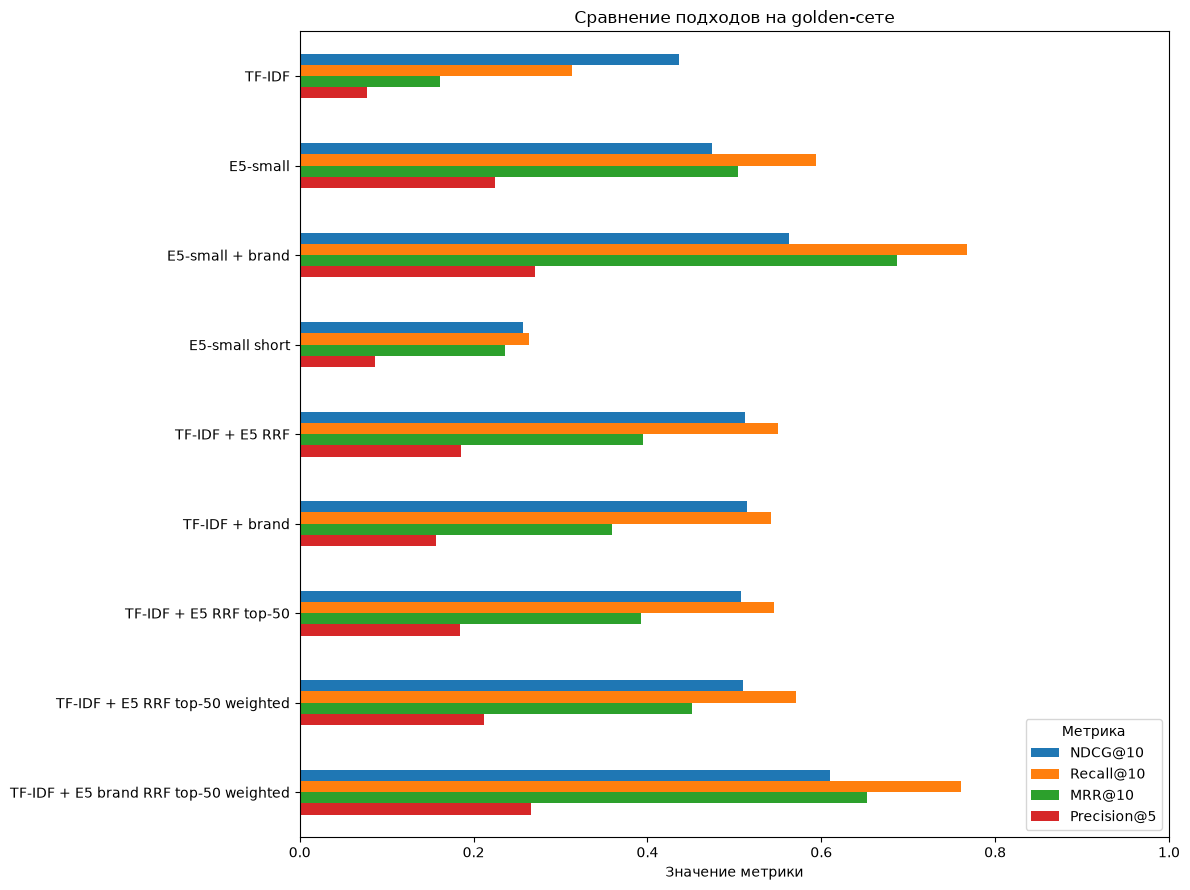

🏃 View run e5_brand at: https://mlflow-ds-20260428-9c124b2073.infra.data-science.education-services.ru/#/experiments/1/runs/b787e1f3603a47e7979af24159412cd4
🧪 View experiment at: https://mlflow-ds-20260428-9c124b2073.infra.data-science.education-services.ru/#/experiments/1
График и сводная таблица обновлены в запуске e5_brand


In [73]:
comparison_metrics = ["NDCG@10", "Recall@10", "MRR@10", "Precision@5"]
comparison = all_metrics_summary[comparison_metrics]

ax = comparison.plot.barh(figsize=(12, 9))
ax.set_title("Сравнение подходов на golden-сете")
ax.set_xlabel("Значение метрики")
ax.set_ylabel("")
ax.set_xlim(0, 1)
ax.invert_yaxis()
ax.legend(title="Метрика", loc="lower right")

plt.tight_layout()
comparison_path = MLFLOW_ARTIFACTS_DIR / "comparison.png"
plt.savefig(comparison_path, dpi=150, bbox_inches="tight")
plt.show()

runs = mlflow.search_runs(
    experiment_ids=[experiment.experiment_id],
    filter_string=(
        "tags.mlflow.runName = 'e5_brand' "
        "AND attributes.status = 'FINISHED'"
    ),
    order_by=["attributes.start_time DESC"],
    max_results=1
)

assert not runs.empty, "Успешный запуск e5_brand не найден"

with mlflow.start_run(run_id=runs.iloc[0]["run_id"]):
    mlflow.log_artifact(
        str(comparison_path),
        artifact_path="comparison"
    )
    mlflow.log_artifact(
        str(MLFLOW_ARTIFACTS_DIR / "metrics_summary.csv"),
        artifact_path="comparison"
    )

print("График и сводная таблица обновлены в запуске e5_brand")

In [69]:
error_query_ids = metrics_by_query_brand.sort_values(
    "NDCG@10", kind="stable"
)["query_id"].head(3)
for query_id in error_query_ids:
    labels = queries_train[queries_train["query_id"].eq(query_id)]
    query = labels["query_text"].iloc[0]
    results = search_semantic_brand(query, top_k=5).merge(
        labels[["item_id", "relevance"]],
        left_on="imt_id",
        right_on="item_id",
        how="left",
        validate="one_to_one"
    ).drop(columns="item_id")
    relevant_products = labels[
        labels["relevance"].ge(RELEVANCE_THRESHOLD)
    ].merge(
        eval_catalog_brand[["imt_id", "imt_name", "brand_name", "product_text"]],
        left_on="item_id",
        right_on="imt_id",
        how="left",
        validate="many_to_one"
    )
    print("Запрос:", query)
    print("Первые пять результатов:")
    display(results)
    print("Релевантные товары по разметке:")
    display(relevant_products[["imt_id", "imt_name", "brand_name", "relevance"]])
    for row in relevant_products.itertuples(index=False):
        print(f"\nimt_id: {row.imt_id}\n{row.product_text}")

Запрос: рубашки с карманами
Первые пять результатов:


,imt_id,imt_name,subj_name,score,relevance
0,10152298,Рубашка,Рубашки,0.871803,NaN
1,10006235,Рубашка,Рубашки,0.868762,NaN
2,10006214,Рубашка,Рубашки,0.866600,NaN
3,10006206,Рубашка,Рубашки,0.866497,NaN
4,10006217,Рубашка,Рубашки,0.866250,NaN


Релевантные товары по разметке:


,imt_id,imt_name,brand_name,relevance
0,1014070,Рубашка,Viaggio bambini,3



imt_id: 1014070
Рубашка
Рубашки
Viaggio bambini
Прекрасная рубашка с отложным воротником и длинными рукавами. Модель с застежкой на пуговицы. На груди изделие дополнено накладным карманом.
Запрос: бежевые футболки
Первые пять результатов:


,imt_id,imt_name,subj_name,score,relevance
0,10050479,Футболка,Футболки,0.886781,NaN
1,10149898,Футболка Для Бега Own The Run,Футболки,0.886473,NaN
2,10050486,Футболка с принтом,Футболки,0.882219,NaN
3,10050485,Футболка с принтом,Футболки,0.882006,NaN
4,10050474,Футболка с принтом,Футболки,0.881583,NaN


... (3 outputs left out)

,imt_id,imt_name,subj_name,score,relevance
0,10057603,Джинсы BIG SIZE Classic,Джинсы,0.899469,NaN
1,10021548,Джинсы,Джинсы,0.895430,NaN
2,10021550,Джинсы,Джинсы,0.894776,NaN
3,10152416,"Джинсы классические, однотонные",Джинсы,0.893700,NaN
4,10016400,Джинсы скинни,Джинсы,0.889511,NaN


Релевантные товары по разметке:


,imt_id,imt_name,brand_name,relevance
0,10035308,Джинсы,ISEE,3



imt_id: 10035308
Джинсы
Джинсы
ISEE
Мы рекомендуем перед выбором сверять Ваши параметры с таблицей размеров, размещённой в фото в карточке товара. Джинсы мужские сшиты из мягкого денима с добавлением полиэфира и эластана, обеспечивающим комфортную посадку изделия по фигуре. Джинсы с легким эффектом "потертости", удобная средняя посадка изделия, шлевки для ремня, зауженный крой брючин, классические "пять карманов", застежка на "молнию" и пуговицу. Джинсовые брюки являются атрибутом повседневной одежды любого мужчины подойдут как домашняя одежда, в офис, для деловой встречи, на вечеринку или свидание в сочетании с мужской футболкой, рубашкой, джемпером, кардиганом, водолазкой торговой марки ISEE. Джинсы подойдут в подарок мужу, папе, любимому на день рождения и 23 февраля. Нас ищут: мужские джинсы летние, брюки мужские летние классические, брюки мужские летние, джинсы мужские прямые, джинсы мужские классические, джинсы мужские больших размеров.


### Разбор запросов с низким NDCG@10
1. **«Рубашки с карманами».** Модель возвращает рубашки, но по названиям нельзя проверить наличие карманов. У размеченного релевантного товара карман явно указан в описании. Возможная причина ошибки — недостаточный учёт конкретного признака; для подтверждения нужно проверить описания найденных товаров.
2. **«Бежевые футболки».** Цвет — важное условие запроса, но отдельное поле цвета не включено в product_text. В описании размеченного товара одновременно упоминаются сиреневый и бежевый варианты, что усложняет поиск на уровне карточки. При дальнейшем развитии стоит проверить использование цвета и фильтрацию по вариантам товара.
3. **«Классические джинсовые джинсы».** В выдаче есть «Джинсы BIG SIZE Classic» и «Джинсы классические, однотонные». По названиям они выглядят подходящими, однако не имеют оценок для этого запроса. Этот пример показывает ограничение неполной разметки: потенциально полезные результаты получают нулевой вклад в метрику.

Во всех трёх случаях требуется дополнительная разметка найденных товаров. Значение NaN означает отсутствие оценки, а не нерелевантность. По этим примерам нельзя однозначно отделить ошибки модели от недостаточного покрытия разметки.

<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Разбор ошибок написан зрело. Ты не ограничился фразой «модель ошибается», а для каждого запроса вывел и выдачу, и размеченные релевантные товары с их текстом, и разделил три разные причины: признак спрятан в описании, цвет не входит в текст карточки, разметка неполная. Замечание о том, что <code>NaN</code> означает отсутствие оценки, а не нерелевантность, и что по этим примерам нельзя отделить ошибку модели от дыр в разметке, говорит о хорошем понимании того, как устроена оценка.

Куда можно пойти дальше:
<ul>
<li>ещё на первой неделе ты завёл флаг <code>has_description</code> «для последующего анализа качества поиска», но так им и не воспользовался. Метрики по запросам уже лежат в таблицах: сравни качество на запросах, где релевантный товар с описанием и без него;</li>
<li>полезно посмотреть не только на худшие запросы лучшей модели, но и на запросы, где TF-IDF обходит E5. Таких должно быть немало, и именно они подскажут, в каком виде нужен гибрид;</li>
<li>на графике сравнения модели стоят по оси X, а метрики в легенде. Если поменять их местами, сравнивать подходы внутри одной метрики будет проще.</li>
</ul>
</div>

### 4. Финальные выводы

**4.1. Сводная таблица.** Все подходы на одних данных, с одинаковыми порогом и K. Укажите лучшую конфигурацию и метрики, по которым был сделан вывод.

**4.2. Качественный анализ.** Числа показывают не всю картину. Возьмите запросы, где лучший подход всё ещё ошибается, и опишите характер ошибок.

**4.3. Ограничения оценки.** Перечислите ограничения модели и данных, на которых проводились эксперименты. Например:

- разметка синтетическая и пулированная;
- каталог оценки меньше реального;
- запросы сгенерированы, а не собраны от пользователей.

Этот раздел не ослабляет работу, а усиливает её: специалист, понимающий границы своего решения, вызывает больше доверия.

**4.4. Рекомендация бизнесу.** Скажите заказчику, внедрять ли ему векторный поиск или нет, в каком виде его лучше реализовывать, в каких сценариях он будет помогать, а где может ошибаться.

**4.5. Дальнейшие шаги.** Перечислите возможные действия, которые могли бы улучшить результат:

- использовать реальные логи запросов вместо синтетических;
- перейти на ANN-индекс при росте каталога;
- применить фильтры по атрибутам поверх векторного поиска.

Все возможные шаги обоснуйте.


*Ваши выводы:*

### Итоги сравнения

Сравнил 9 конфигураций на одинаковых 700 запросах golden-сета и каталоге из 4256 карточек. Порог релевантности — 2, значения K — 1, 3, 5 и 10. Для NDCG использовал всю шкалу оценок.

| Подход | NDCG@10 | Recall@10 | MRR@10 | Precision@5 |
|---|---:|---:|---:|---:|
| TF-IDF | 0,4364 | 0,3137 | 0,1618 | 0,0777 |
| E5-small | 0,4741 | 0,5942 | 0,5044 | 0,2246 |
| TF-IDF + бренд | 0,5144 | 0,5424 | 0,3592 | 0,1571 |
| E5-small + бренд | 0,5633 | 0,7674 | 0,6867 | 0,2711 |
| E5-small без описания | 0,2573 | 0,2635 | 0,2360 | 0,0871 |
| RRF по всему каталогу | 0,5119 | 0,5504 | 0,3950 | 0,1851 |
| RRF top-50 | 0,5081 | 0,5457 | 0,3925 | 0,1840 |
| RRF top-50 с весами | 0,5101 | 0,5706 | 0,4508 | 0,2123 |
| RRF top-50 с весами и брендом | 0,6105 | 0,7606 | 0,6530 | 0,2663 |

В вариантах с разными весами вклад TF-IDF равен 0,3, E5 — 0,7. В последнем варианте бренд добавлен в тексты обоих методов.

Добавление бренда помогло обоим подходам. При одинаковом составе текста E5 с брендом превосходит TF-IDF с брендом по всем рассчитанным метрикам. Основной прирост E5 пришёлся на запросы с найденным названием бренда: NDCG@10 вырос с 0,3919 до 0,6670. Удаление описания, наоборот, ухудшило результат.

Одного лидера по всем метрикам нет. Гибрид с брендом получил лучший NDCG@10 — 0,6105. E5 с брендом лучше по Recall@10 и MRR@10, а также чаще находит подходящий товар на первой позиции: Precision@1 составляет 0,5743 против 0,5357 у гибрида.

Для сценария, где важнее быстро показать первый подходящий товар, сохраняю выбор E5 с брендом. Гибрид с брендом рассматриваю как альтернативу для проверки качества всей первой десятки.

На 300 тестовых запросах E5 с брендом получил NDCG@10 = 0,5696, Recall@10 = 0,7828 и MRR@10 = 0,6477. В 87% запросов в топ-10 есть хотя бы один товар с оценкой не ниже 2. Новые проверки после ревью проводились на golden-сете; тестовые результаты относятся только к E5 с брендом и не подтверждают преимущество нового гибрида.

### Качественный анализ

Разобрал запросы «рубашки с карманами», «бежевые футболки» и «классические джинсовые джинсы». E5 с брендом возвращает товары нужной категории, но по названиям нельзя проверить наличие карманов, цвет или крой.

Первые пять результатов каждого из этих запросов не имеют оценок. Поэтому низкая метрика здесь может отражать как ошибки поиска, так и неполноту разметки.

### Ограничения

- Запросы синтетические и могут отличаться от реальных запросов покупателей.
- Оценка проводится на 4256 карточках. Качество выбранного решения на полном каталоге из 48376 карточек не подтверждено.
- Описания есть у 77,51% карточек пула оценки и только у 37,39% полного каталога. Поэтому на полном каталоге польза описаний может быть меньше.
- Неразмеченные товары получают 0, хотя среди них могут быть подходящие.
- Карточка может объединять несколько вариантов товара, поэтому цвет и другие характеристики не всегда однозначны.
- E5-small ограничен 512 токенами. В базовом шаблоне лимит превышали 1,25% карточек.
- TF-IDF ограничен 100000 признаками: часть редких слов брендов не попадает в словарь. Равные скоры дают порядок, зависящий от расположения строк. Ограничение RRF до top-50 не исключает попадания товаров с нулевым лексическим скором.
- Golden-сет многократно использовался для сравнения конфигураций. Новые варианты гибрида пока не проверены на независимой выборке.
- MRR рассчитан по первой десятке; в MLflow он также записан как mrr с параметром mrr_cutoff=10.
- Скорость под нагрузкой и влияние на продажи не измерялись.

### Рекомендация бизнесу

Рекомендую пилот E5-small с названием, категорией, брендом и описанием товара. На подготовленной разметке он лучше лексического поиска даже после добавления бренда в TF-IDF. Особенно заметно улучшение на запросах с названием бренда.

Гибрид с брендом стоит включить в пилот как альтернативу: он лучше по NDCG@10, но уступает по качеству первой позиции. Полностью заменять действующий поиск только на основании этих экспериментов рано.

Для точных условий — цвета, размера и бренда — нужны дополнительные проверки или фильтры: семантическая близость не гарантирует их соблюдения.

### Дальнейшие шаги

1. Собрать реальные запросы и разметить выдачу разных методов.
2. Сравнить E5 с брендом и гибрид на новой независимой выборке.
3. Добавить фильтры по характеристикам с учётом вариантов товара.
4. Проверить качество и задержку на полном каталоге.
5. Провести A/B-тест по кликам, добавлениям в корзину и покупкам.

<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Финальные выводы закрывают все пять пунктов задания и написаны языком, понятным заказчику. Сводная таблица на одних данных, конкретная рекомендация (пилот, а не немедленная замена), сценарии риска (цвет, размер, бренд, точные характеристики), следующие шаги с A/B-тестом по кликам и покупкам.

Раздел ограничений один из самых полных, что я видел в этом проекте: кроме стандартных пунктов про синтетику и пул, ты указал обрезку по 512 токенам с конкретной долей, склейку вариантов товара в одной карточке, ограничение MRR первой десяткой и то, что скорость и влияние на продажи не измерялись.

💡 После доработок выше (TF-IDF с брендом, baseline на test, гибрид на шаблоне с брендом) обнови, пожалуйста, таблицу и формулировку рекомендации. Возможно, рекомендовать стоит уже не чистый векторный поиск, а гибрид, и это нужно сказать заказчику прямо.
</div>

<div style="border:solid Chocolate 2px; padding: 40px">

<b>Общий вывод по проекту ревьювера v1</b>:

Спасибо за проект! Ты приложил много усилий, чтобы довести его до конца, проделана большая работа, и это видно невооруженным глазом, ты большой молодец!

<b>Отмечу положительные моменты</b>:

<ol>
<li>Все решения по данным подкреплены анализом: выбор категорий, уровень индексации, правило дедупликации, состав текста карточки. Ход мыслей понятен на каждом шаге.</li>
<li>Аккуратная работа с моделью: префиксы E5, проверка длины токенизатором, нормировка эмбеддингов. Метрики реализованы без ошибок и проверены на игрушечном примере.</li>
<li>Эксперименты поставлены по правилу «одна гипотеза, одно изменение», отрицательный результат честно записан как отрицательный, test использован один раз.</li>
<li>Образцовое логирование в MLflow с гипотезами и выводами в тегах.</li>
<li>Очень сильные разделы про ограничения оценки и разбор ошибок: ты хорошо понимаешь, чему в полученных цифрах можно верить, а чему нет.</li>
</ol>

<b>На что стоит обратить внимание</b>:

<ol>
<li>В разделе «Каталог для поиска и оценки» есть расчёты, но нет выводов: почему метрика на полном каталоге так сильно отличается и что показывает распределение оценок.</li>
<li>Не обоснованы порог релевантности и выбор модели эмбеддингов.</li>
<li>Baseline сравнивается с лучшей моделью в неравных условиях: бренд добавлен только для E5, а на test baseline не посчитан.</li>
<li>Гибридный поиск стоит доработать: глубина слияния, веса, шаблон с брендом.</li>
<li>Много повторяющегося кода в экспериментах и логировании, его стоит свернуть в функции.</li>
</ol>

Критичных замечаний у меня нет, <b>проект принят</b>. Жёлтые комментарии советую всё же отработать: с ними проект станет заметно сильнее, и его не стыдно будет показать в портфолио.

<b>Удачи в дальнейшем обучении!</b>
</div>